# 10 · Interpretabilidad y explicabilidad: ¿qué está haciendo el modelo?

Este es un módulo de Neural Networks 1002. Supone las redes convolucionales del módulo 05 de Neural Networks 1001, el transformer del módulo 09 y el modelo de lenguaje del módulo 10 (GPT desde cero) y, de forma más laxa, las ideas de alineación del módulo 01 de este curso. Una red entrenada es un montón de números que da respuestas correctas la mayor parte del tiempo. La **interpretabilidad** pregunta *qué calculan los números*; la **explicabilidad** pide una *razón* legible para una respuesta concreta. Ambas son fáciles de hacer mal: un mapa de calor bonito no es evidencia de que el modelo "mira" lo que el mapa resalta. Por eso en este módulo cada método se **mide**: comprobamos si su salida sobrevive a una prueba de aleatorización, si borrar lo que señala cambia de verdad la predicción y si es capaz de encontrar un defecto que plantamos a propósito.

En este notebook construirás, en la CPU de un portátil:

1. el **vocabulario** (interpretable por diseño frente a post-hoc, global frente a local, explicación frente a afirmación causal) y las razones para interpretar;
2. **modelos interpretables como vara de medir**: un modelo lineal y un árbol pequeño en una tarea tabular cuya regla verdadera conocemos;
3. **atribución de características en datos tabulares**: importancia por permutación, gradiente por entrada, **gradientes integrados**, **valores de Shapley** exactos (SHAP, SHapley Additive exPlanations) con una versión Monte Carlo, y **LIME** (Local Interpretable Model-agnostic Explanations), comparados con la verdad conocida;
4. **visión**: saliencia, SmoothGrad, gradientes integrados y **Grad-CAM** (gradient-weighted class activation mapping) en una CNN pequeña, la **prueba de cordura** de Adebayo et al. (¿cambian las atribuciones cuando se aleatorizan los pesos?), **curvas de borrado** como prueba de fidelidad, un **atajo** plantado (una marca de agua) que la atribución revela y Grad-CAM en una ResNet-18 preentrenada;
5. **lenguaje**: **sondas lineales** sobre los estados ocultos de un transformer preentrenado pequeño y una medición de si **la atención es una explicación**;
6. una primera mirada a la **interpretabilidad mecanicista**: un modelo de juguete que aprende una **cabeza de inducción**, encontrada por ablación y por **parcheo de activaciones**, y un **autoencoder disperso** de juguete que recupera características almacenadas en superposición;
7. los **límites y el mal uso** de las explicaciones.

**Contenido**

1. Por qué interpretar y el vocabulario
2. Modelos interpretables como vara de medir (tarea tabular con una regla conocida)
3. Atribución de características en datos tabulares: permutación, gradientes, Shapley, LIME
4. Visión: mapas de atribución, Grad-CAM, pruebas de cordura y curvas de borrado
5. Un atajo plantado: ¿puede la atribución encontrarlo?
6. Grad-CAM en una ResNet-18 preentrenada
7. Modelos de lenguaje: sondas y la atención no es explicación
8. Interpretabilidad mecanicista: una cabeza de inducción y un autoencoder disperso
9. Límites y mal uso de las explicaciones
10. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [Módulo 05 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) | convoluciones, mapas de características, pooling, la idea de ResNet |
| [Módulo 09 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) | autoatención, el flujo residual, atención multicabeza |
| [Módulo 10 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/) | predicción del siguiente token, estados ocultos de un modelo de lenguaje |
| [Módulo 01 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/01-rlhf-y-alineacion/) | por qué nos importa que el comportamiento de un modelo coincida con lo que pretendíamos |

¿Nuevo en PyTorch? El [curso Python 1001, sección sobre frameworks de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo introduce. Todo se ejecuta en pocos minutos en una CPU (unos 3 minutos en un entorno limpio de 2 CPU, de 8 a 10 en un portátil ocupado) con semillas aleatorias fijas. La primera vez lee tres archivos pequeños en caché (Fashion-MNIST, Banking77, DistilBERT; unos 270 MB en total, con las licencias en las secciones que los usan) y un punto de control de ResNet-18 (45 MB). La mayor parte del código tabular y de atribución está escrita aquí desde cero en pocas líneas cada uno, para que veas qué calculan las versiones de las bibliotecas.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/10_interpretabilidad_y_explicabilidad.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 3 minutos, con un pico de memoria de unos 1,6 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'PIL': 'pillow',
    'huggingface_hub': 'huggingface_hub',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'shap': 'shap',
    'skimage': 'scikit-image',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'torchvision': 'torchvision',
    'transformers': 'transformers',
    'pyarrow': 'pyarrow',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, io, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()

def rank_corr(a, b):
    # correlación de rangos de Spearman entre dos vectores (segura ante nan)
    r = spearmanr(a, b)[0]
    return 0.0 if np.isnan(r) else float(r)

## 1. Por qué interpretar y el vocabulario

Cuatro razones aparecen una y otra vez.

| Razón | Pregunta a la que responde | Ejemplo |
|---|---|---|
| **Depuración** | ¿Acierta el modelo por la razón equivocada? | un clasificador de lesiones de piel que aprendió que las reglas (presentes en las fotografías de casos malignos) significan cáncer |
| **Confianza y adopción** | ¿Puede comprobar la salida quien la usa? | un médico que quiere ver qué mediciones determinaron una puntuación de riesgo |
| **Regulación y responsabilidad** | ¿Se puede dar la razón de una decisión a la persona afectada? | decisiones de crédito, donde una persona puede tener derecho a una explicación; véanse el Reglamento General de Protección de Datos y la Ley de IA de la UE |
| **Ciencia** | ¿Qué descubrió el modelo? | una red que predice bien una propiedad de una molécula puede haber encontrado un patrón que vale la pena conocer |

Las palabras se usan con poco rigor, así que las fijamos.

* **Interpretable por diseño** (también *intrínsecamente interpretable*): el modelo es lo bastante pequeño o estructurado para leerse directamente, como un modelo lineal, un árbol de decisión corto o una regla de puntuación. La explicación **post-hoc** toma un modelo opaco ya entrenado y produce una explicación después. Rudin ([2019](https://arxiv.org/abs/1811.10154)) sostiene que en decisiones de alto riesgo hay que preferir la primera cuando es lo bastante precisa, porque una explicación post-hoc no es, por construcción, lo que el modelo calcula realmente.
* La explicación **global** describe todo el modelo ("¿qué características importan en promedio?"); la **local** describe una predicción ("¿por qué este paciente?").
* Los métodos **agnósticos al modelo** solo llaman al modelo como caja negra (importancia por permutación, LIME, valores de Shapley); los **específicos del modelo** lo abren (gradientes, Grad-CAM, sondas, circuitos).
* Una **explicación** no es una **afirmación causal sobre el mundo**. Una atribución dice *cómo usa el modelo sus entradas*. No dice que cambiar la entrada en la realidad cambiaría el resultado. Lo hacemos concreto en la sección 3.
* Dos nociones de calidad que mediremos en lugar de suponer: la **fidelidad** (¿refleja la explicación lo que el modelo hace realmente?) y la **plausibilidad** (¿le parece razonable a una persona?). Son distintas, y un método puede ser muy plausible e infiel.

A lo largo del módulo hacemos tres preguntas a cada método: *¿recupera una verdad que plantamos?*, *¿cambia cuando se destruye el modelo?* y *¿actuar según él cambia la predicción como promete?*

## 2. Modelos interpretables como vara de medir

Necesitamos una tarea en la que **conozcamos la respuesta**. Generamos una tabla sintética de "riesgo del paciente" (mediciones genéricas de tipo sanitario, nada real). Hay ocho características estandarizadas. La probabilidad verdadera del resultado depende solo de **tres** de ellas e incluye una interacción:

$$\text{logit} = 1.4\,\text{age} + 1.0\,\text{sys\_bp} + 1.2\,\text{age}\times\text{bmi} - 0.2, \qquad P(\text{resultado}) = \sigma(\text{logit}),$$

donde $\sigma(z) = 1/(1+e^{-z})$ es la función logística. Las otras cinco características son señuelos: `glucose` está fuertemente correlacionada con `bmi` (así que *parece* útil) pero no tiene efecto propio, y `cholesterol`, `sleep`, `steps` y `noise` son independientes de todo. Como escribimos la regla, cualquier método de atribución puede puntuarse: ¿cuánto de su crédito cae en `age`, `bmi` y `sys_bp`?

Entrenamos tres modelos: una regresión logística y un árbol de decisión de profundidad 3 (ambos legibles) y un pequeño perceptrón multicapa (MLP, 8-32-32-1), y los comparamos con el **oráculo** (la propia probabilidad verdadera).

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

FEATS = ["age", "bmi", "glucose", "sys_bp", "cholesterol", "sleep", "steps", "noise"]
USED = [0, 1, 3]                       # características que la regla verdadera sí usa
rng = np.random.default_rng(0)
N = 6000
age, bmi, bp = rng.normal(size=N), rng.normal(size=N), rng.normal(size=N)
glucose = 0.8 * bmi + 0.6 * rng.normal(size=N)       # señuelo correlacionado
others = rng.normal(size=(N, 3))
chol, sleep, steps = others[:, 0], others[:, 1], others[:, 2]
noise = rng.normal(size=N)
X = np.column_stack([age, bmi, glucose, bp, chol, sleep, steps, noise]).astype(np.float32)
true_logit = 1.4 * age + 1.0 * bp + 1.2 * age * bmi - 0.2
p_true = 1 / (1 + np.exp(-true_logit))
y = (rng.random(N) < p_true).astype(int)
Xtr, Xte, ytr, yte, ptr_true, pte_true = X[:4500], X[4500:], y[:4500], y[4500:], p_true[:4500], p_true[4500:]
print(f"tasa del resultado {y.mean():.2f}; correlación(bmi, glucose) = {np.corrcoef(bmi, glucose)[0,1]:.2f}")

lr = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr, ytr)

class MLP(nn.Module):
    def __init__(s, d=8, h=32):
        super().__init__(); s.net = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))
    def forward(s, x): return s.net(x).squeeze(-1)          # devuelve el LOGIT

torch.manual_seed(0)
mlp = MLP()
opt = torch.optim.AdamW(mlp.parameters(), 3e-3, weight_decay=1e-3)
Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32)
for step in range(600):
    loss = F.binary_cross_entropy_with_logits(mlp(Xt), yt)
    opt.zero_grad(); loss.backward(); opt.step()
mlp.eval()
f_mlp = lambda A: mlp(torch.as_tensor(np.asarray(A, dtype=np.float32))).detach().numpy()     # entra numpy, sale el logit

def score(name, p):
    return dict(model=name, accuracy=accuracy_score(yte, p > 0.5), auc=roc_auc_score(yte, p), log_loss=log_loss(yte, np.clip(p, 1e-6, 1 - 1e-6)))
rows = [score("oráculo (probabilidad verdadera)", pte_true), score("regresión logística", lr.predict_proba(Xte)[:, 1]),
        score("árbol de decisión, profundidad 3", tree.predict_proba(Xte)[:, 1]), score("MLP 8-32-32-1", 1 / (1 + np.exp(-f_mlp(Xte))))]
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\ncoeficientes de la regresión logística (por desviación estándar):")
print(pd.Series(lr.coef_[0], index=FEATS).round(2).to_string())
print("\nel árbol de profundidad 3, como reglas:")
print(export_text(tree, feature_names=FEATS))

tasa del resultado 0.46; correlación(bmi, glucose) = 0.81


                           model  accuracy   auc  log_loss
oráculo (probabilidad verdadera)     0.771 0.853     0.472
             regresión logística     0.741 0.801     0.543
árbol de decisión, profundidad 3     0.723 0.773     0.567
                   MLP 8-32-32-1     0.732 0.815     0.571

coeficientes de la regresión logística (por desviación estándar):
age            1.08
bmi            0.02
glucose        0.06
sys_bp         0.87
cholesterol   -0.00
sleep          0.01
steps          0.04
noise          0.08

el árbol de profundidad 3, como reglas:
|--- age <= -0.15
|   |--- sys_bp <= 0.65
|   |   |--- bmi <= -1.32
|   |   |   |--- class: 1
|   |   |--- bmi >  -1.32
|   |   |   |--- class: 0
|   |--- sys_bp >  0.65
|   |   |--- bmi <= -0.17
|   |   |   |--- class: 1
|   |   |--- bmi >  -0.17
|   |   |   |--- class: 0
|--- age >  -0.15
|   |--- sys_bp <= 0.05
|   |   |--- age <= 0.89
|   |   |   |--- class: 0
|   |   |--- age >  0.89
|   |   |   |--- class: 1
|   |--- sys_bp >  

**Lectura.** El oráculo, que conoce la probabilidad verdadera, alcanza solo 0.771 de exactitud: el resultado es aleatorio dadas las características, así que ese es el techo. Los modelos legibles no están lejos (regresión logística 0.741, árbol de profundidad 3 0.723) y el MLP (0.737) no es mejor que la regresión logística; su log-loss (0.574) es incluso peor (0.543 la regresión logística), señal de sobreajuste. Con 1500 filas de prueba una exactitud tiene un error estándar de unos 1.1 puntos, así que estos tres modelos están estadísticamente cerca. La regresión logística es totalmente legible y da los efectos principales correctos (age 1.08, sys_bp 0.87), pero asigna a `bmi` un coeficiente de 0.02: `bmi` importa solo a través de su producto con `age`, que un modelo lineal no puede expresar. Una lectura simple de "qué coeficiente es grande" llamaría irrelevante a `bmi`, lo cual es falso. El árbol sí usa `bmi` en sus divisiones, como parte de una regla fácil de leer pero también aproximada. Esta es la primera lección: **un modelo legible es legible en lo que puede representar**.

## 3. Atribución de características en datos tabulares

Una **atribución** asigna a cada característica de entrada un número que dice cuánto contribuyó a una predicción. Explicamos el **logit** (la puntuación previa a la sigmoide) del MLP, porque se presta a la aditividad. Todos los métodos de abajo están escritos en pocas líneas.

* **Importancia por permutación** (global, agnóstica al modelo): se baraja una característica en el conjunto de prueba y se mide cuánto aumenta la pérdida. Una característica que el modelo ignora no cuesta nada.
* **Gradiente por entrada** (local): $\partial f/\partial x_j \cdot (x_j - \bar{x}_j)$, la pendiente del modelo escalada por lo lejos que está esta entrada de la entrada media $\bar{x}$. Es una aproximación de primer orden, exacta solo para modelos lineales.
* **Gradientes integrados** (Sundararajan et al., [2017](https://arxiv.org/abs/1703.01365)): se promedia el gradiente a lo largo del camino recto desde una entrada de referencia $x'$ hasta la entrada $x$ y se multiplica por el desplazamiento,
$$\text{IG}_j(x) = (x_j - x'_j)\int_0^1 \frac{\partial f\big(x' + \alpha (x - x')\big)}{\partial x_j}\, d\alpha ,$$
aproximado por una suma de $m$ pasos ($\alpha$ es la posición a lo largo del camino). Su propiedad definitoria es la **completitud**: $\sum_j \text{IG}_j(x) = f(x) - f(x')$, que podemos comprobar numéricamente.
* **Valores de Shapley** (Lundberg y Lee, [2017](https://arxiv.org/abs/1705.07874), el marco SHAP; la idea viene de la teoría de juegos cooperativos): el crédito de la característica $j$ es su **contribución marginal media** sobre todos los órdenes en que podrían revelarse las características. Para un conjunto $S$ de características "conocidas", sea $v(S)$ la predicción media cuando las características de $S$ toman los valores de $x$ y el resto se extrae de datos de fondo. Entonces
$$\phi_j = \sum_{S \subseteq \{1..d\} \setminus \{j\}} \frac{|S|!\,(d-|S|-1)!}{d!}\,\big[v(S \cup \{j\}) - v(S)\big],$$
con $d$ el número de características y $|S|$ el tamaño de $S$. También cumplen la completitud, $\sum_j \phi_j = f(x) - \mathbb{E}[f]$. Con $d = 8$ solo hay $2^8 = 256$ conjuntos, así que los calculamos **exactamente**; con muchas características se muestrean órdenes aleatorios (una estimación Monte Carlo, que también implementamos).
* **LIME** (Ribeiro et al., [2016](https://arxiv.org/abs/1602.04938)): se perturba la entrada muchas veces, se consulta la caja negra y se ajusta un **modelo lineal ponderado** cuyos pesos favorecen las perturbaciones cercanas a la entrada. Los coeficientes del modelo lineal son la explicación local. Usamos la versión continua para datos tabulares, donde el tamaño del vecindario (el **ancho del núcleo**) es una elección libre.

La biblioteca `shap` implementa estimadores de Shapley con atajos rápidos para árboles y redes profundas; no hace falta para $d = 8$, y nuestra enumeración exacta es la cantidad que ella estima.

In [3]:
def permutation_importance(f_prob_loss, X, y, repeats=5, seed=0):
    r = np.random.default_rng(seed); base = f_prob_loss(X, y); imp = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        for _ in range(repeats):
            Xp = X.copy(); Xp[:, j] = r.permutation(Xp[:, j]); imp[j] += f_prob_loss(Xp, y) - base
    return imp / repeats

mlp_loss = lambda A, t: log_loss(t, np.clip(1 / (1 + np.exp(-f_mlp(A))), 1e-6, 1 - 1e-6))
perm = permutation_importance(mlp_loss, Xte, yte)

def grad_x_input(model, x, baseline):
    x = torch.as_tensor(x, dtype=torch.float32).clone().requires_grad_(True)
    model(x).sum().backward()
    return (x.grad * (x.detach() - torch.as_tensor(baseline))).numpy()

def integrated_gradients_tab(model, x, baseline, steps=64):
    x = torch.as_tensor(x, dtype=torch.float32); b = torch.as_tensor(baseline, dtype=torch.float32)
    alphas = (torch.arange(steps) + 0.5) / steps                     # regla del punto medio
    path = (b + alphas[:, None, None] * (x - b)[None]).reshape(-1, x.shape[1]).requires_grad_(True)
    model(path).sum().backward()
    g = path.grad.reshape(steps, x.shape[0], -1).mean(0)
    return (g * (x - b)).detach().numpy()

def shapley_exact(f, x, B):
    # valores de Shapley intervencionales exactos para UNA entrada x (d,), filas de fondo B (nb, d); f lleva (n,d)->(n,)
    d = len(x); S = 2 ** d
    masks = ((np.arange(S)[:, None] >> np.arange(d)) & 1).astype(bool)         # la fila i es el conjunto cuya máscara de bits es i
    Z = np.where(masks[:, None, :], x[None, None, :], B[None, :, :])           # (S, nb, d)
    v = f(Z.reshape(-1, d)).reshape(S, -1).mean(1)
    size = masks.sum(1)
    w = np.array([math.factorial(s) * math.factorial(d - s - 1) / math.factorial(d) if s < d else 0.0 for s in range(d + 1)])
    phi = np.zeros(d)
    for j in range(d):
        without = np.where(~masks[:, j])[0]
        phi[j] = (w[size[without]] * (v[without | (1 << j)] - v[without])).sum()
    return phi, v[0], v[-1]

def shapley_mc(f, x, B, n_perm, seed=0):
    # Shapley Monte Carlo: contribución marginal media sobre órdenes aleatorios de características y filas de fondo aleatorias
    r = np.random.default_rng(seed); d = len(x)
    z = B[r.integers(0, len(B), n_perm)].copy(); prev = f(z); phi = np.zeros(d)
    orders = np.argsort(r.random((n_perm, d)), axis=1)
    for pos in range(d):
        j = orders[:, pos]
        z[np.arange(n_perm), j] = x[j]
        cur = f(z); phi_add = cur - prev
        np.add.at(phi, j, phi_add); prev = cur
    return phi / n_perm

def lime_tabular(f, x, sd, n=2000, width=2.0, seed=0):
    # LIME continuo: perturbaciones gaussianas (en unidades de desviación estándar), ajuste ridge ponderado por núcleo
    from sklearn.linear_model import Ridge
    r = np.random.default_rng(seed); d = len(x)
    U = r.normal(size=(n, d))                                        # perturbación en unidades de sd
    w = np.exp(-(U ** 2).sum(1) / width ** 2)                        # núcleo de cercanía
    m = Ridge(alpha=1.0).fit(U, f(x + U * sd), sample_weight=w)
    return m.coef_                                                   # pendiente local por sd de cada característica

rb = np.random.default_rng(1)
B = Xtr[rb.choice(len(Xtr), 100, replace=False)]                      # datos de fondo para Shapley
xbar = Xtr.mean(0); sd = Xtr.std(0)
EVAL = Xte[:150]

t0 = time.time()
shap_vals = np.zeros_like(EVAL); base_v = np.zeros(len(EVAL)); fx_v = np.zeros(len(EVAL))
for i, xi in enumerate(EVAL):
    shap_vals[i], base_v[i], fx_v[i] = shapley_exact(f_mlp, xi, B)
t_shap = time.time() - t0
print(f"Shapley exacto para {len(EVAL)} entradas x 256 coaliciones x 100 filas de fondo: {t_shap:.1f} s")
print("completitud (suma de phi + E[f] - f(x)), error absoluto máximo:", f"{np.abs(shap_vals.sum(1) + base_v - fx_v).max():.2e}")

# comprobación 1: en un modelo lineal, los valores de Shapley deben ser coef * (x - media del fondo)
f_lin = lambda A: A @ lr.coef_[0] + lr.intercept_[0]
phi_lin, _, _ = shapley_exact(f_lin, EVAL[0], B)
print("comprobación con modelo lineal, máx |phi - coef*(x - media B)|:", f"{np.abs(phi_lin - lr.coef_[0] * (EVAL[0] - B.mean(0))).max():.2e}")

# gradiente x entrada y gradientes integrados (referencia = media del entrenamiento)
gxi = grad_x_input(mlp, EVAL, xbar)
ig = integrated_gradients_tab(mlp, EVAL, xbar, steps=64)
f0 = f_mlp(xbar[None])[0]
print("completitud de IG, error absoluto máximo de sum(IG) - (f(x) - f(referencia)):", f"{np.abs(ig.sum(1) - (f_mlp(EVAL) - f0)).max():.2e}")
print("completitud del gradiente x entrada, error absoluto máximo (no es completo):", f"{np.abs(gxi.sum(1) - (f_mlp(EVAL) - f0)).max():.2f}")

# LIME (ancho de núcleo 2) y su estabilidad entre dos semillas aleatorias
lime = np.array([lime_tabular(f_mlp, xi, sd, width=2.0, seed=0) * (xi - xbar) / sd for xi in EVAL])    # pendiente x desplazamiento, comparable con phi
lime2 = np.array([lime_tabular(f_mlp, xi, sd, width=2.0, seed=1) * (xi - xbar) / sd for xi in EVAL])
stab = np.mean([rank_corr(np.abs(a), np.abs(b)) for a, b in zip(lime, lime2)])
print(f"estabilidad de LIME, correlación de rangos media de |atribuciones| entre dos semillas: {stab:.2f}")

Shapley exacto para 150 entradas x 256 coaliciones x 100 filas de fondo: 0.9 s
completitud (suma de phi + E[f] - f(x)), error absoluto máximo: 6.56e-07
comprobación con modelo lineal, máx |phi - coef*(x - media B)|: 6.39e-08
completitud de IG, error absoluto máximo de sum(IG) - (f(x) - f(referencia)): 1.02e-01
completitud del gradiente x entrada, error absoluto máximo (no es completo): 9.07


estabilidad de LIME, correlación de rangos media de |atribuciones| entre dos semillas: 0.96


In [4]:
# Shapley Monte Carlo: error respecto a los valores exactos al crecer el número de órdenes muestreados
rows = []
for n_perm in [10, 50, 200, 1000, 5000]:
    err = np.mean([np.abs(shapley_mc(f_mlp, EVAL[i], B, n_perm, seed=i) - shap_vals[i]).mean() for i in range(20)])
    rows.append((n_perm, err))
print(pd.DataFrame(rows, columns=["órdenes muestreados", "error abs. medio por característica"]).round(4).to_string(index=False))

# ¿Coincide la biblioteca shap real? (opcional: solo se ejecuta si está instalada)
try:
    import shap
    ex = shap.KernelExplainer(f_mlp, B[:50])
    sv = ex.shap_values(EVAL[:5], nsamples=2000, silent=True)
    print("shap.KernelExplainer frente a nuestros valores exactos, diferencia absoluta máxima en 5 entradas:", np.abs(sv - shap_vals[:5]).max().round(3))
except Exception as e:
    print("la biblioteca shap no está instalada aquí; se omite la comparación (pip install shap para probarla):", type(e).__name__)

# ancho de núcleo de LIME: acuerdo con Shapley (correlación de rangos por entrada de |atribuciones|)
for width in [0.5, 1.0, 2.0, 4.0]:
    L = np.array([lime_tabular(f_mlp, xi, sd, width=width, seed=0) * (xi - xbar) / sd for xi in EVAL[:60]])
    print(f"ancho de núcleo de LIME {width}: acuerdo de rangos con Shapley = {np.mean([rank_corr(np.abs(a), np.abs(b)) for a, b in zip(L, shap_vals[:60])]):.2f}")

 órdenes muestreados  error abs. medio por característica
                  10                               0.4249
                  50                               0.1999
                 200                               0.1013
                1000                               0.0454
                5000                               0.0194


shap.KernelExplainer frente a nuestros valores exactos, diferencia absoluta máxima en 5 entradas: 0.211
ancho de núcleo de LIME 0.5: acuerdo de rangos con Shapley = 0.45
ancho de núcleo de LIME 1.0: acuerdo de rangos con Shapley = 0.58


ancho de núcleo de LIME 2.0: acuerdo de rangos con Shapley = 0.60
ancho de núcleo de LIME 4.0: acuerdo de rangos con Shapley = 0.62


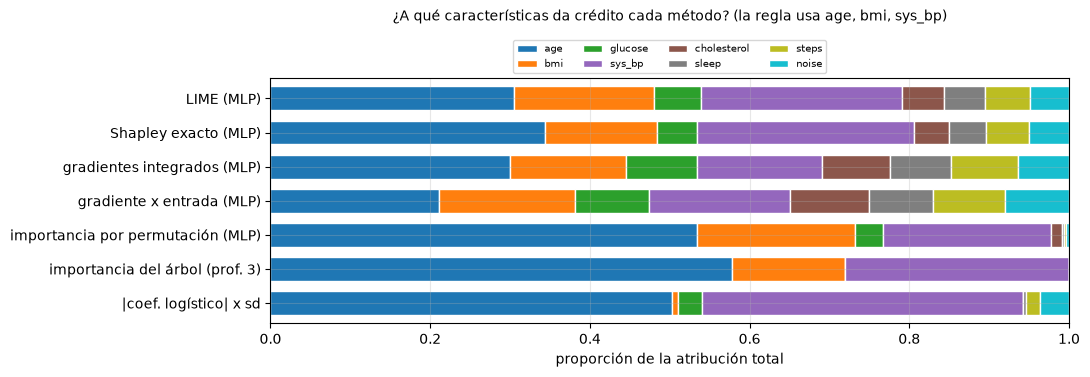

proporción de la atribución en las tres características realmente usadas:
|coef. logístico| x sd               0.912
importancia del árbol (prof. 3)      1.000
importancia por permutación (MLP)    0.942
gradiente x entrada (MLP)            0.558
gradientes integrados (MLP)          0.602
Shapley exacto (MLP)                 0.755
LIME (MLP)                           0.731

MLP: |Shapley| medio del señuelo 'glucose' = 0.23 unidades de logit, frente a 0.65 para 'bmi'

Paciente 39: logit del modelo -17.45, logit medio -0.58
             valor (unid. de sd)  Shapley   LIME     IG
age                        -1.96    -9.59 -14.15 -12.73
bmi                         2.45    -4.85  -6.61  -4.20
glucose                     2.03     0.23   0.31   1.26
sys_bp                     -0.46    -1.30  -1.41  -1.76
cholesterol                -0.26    -0.27  -0.19  -0.04
sleep                      -1.18    -1.03  -1.44  -0.53
steps                       1.85     0.27   1.04   1.73
noise                    

In [5]:
# Comparación global: |atribución| media por característica para cada método, escalada para sumar 1, frente a la regla conocida
glob = {
    "|coef. logístico| x sd": np.abs(lr.coef_[0]) * sd,
    "importancia del árbol (prof. 3)": tree.feature_importances_,
    "importancia por permutación (MLP)": np.clip(perm, 0, None),
    "gradiente x entrada (MLP)": np.abs(gxi).mean(0),
    "gradientes integrados (MLP)": np.abs(ig).mean(0),
    "Shapley exacto (MLP)": np.abs(shap_vals).mean(0),
    "LIME (MLP)": np.abs(lime).mean(0),
}
G = pd.DataFrame({k: v / v.sum() for k, v in glob.items()}, index=FEATS)
fig, ax = plt.subplots(figsize=(11, 4))
G.T.plot.barh(stacked=True, ax=ax, width=0.7, colormap="tab10", edgecolor="white")
ax.set_xlabel("proporción de la atribución total"); ax.legend(ncol=4, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("¿A qué características da crédito cada método? (la regla usa age, bmi, sys_bp)", y=1.2, fontsize=10); plt.tight_layout(); plt.show()

mass = G.loc[[FEATS[i] for i in USED]].sum().round(3)
print("proporción de la atribución en las tres características realmente usadas:")
print(mass.to_string())
print(f"\nMLP: |Shapley| medio del señuelo 'glucose' = {np.abs(shap_vals[:, 2]).mean():.2f} unidades de logit, frente a {np.abs(shap_vals[:, 1]).mean():.2f} para 'bmi'")

# un paciente, explicado localmente
i = int(np.argmax(np.abs(fx_v - base_v)))
local = pd.DataFrame({"valor (unid. de sd)": EVAL[i], "Shapley": shap_vals[i], "LIME": lime[i], "IG": ig[i]}, index=FEATS).round(2)
print(f"\nPaciente {i}: logit del modelo {fx_v[i]:.2f}, logit medio {base_v[i]:.2f}")
print(local.to_string())

**Lectura.** Primero las comprobaciones. Los valores de Shapley exactos cumplen la completitud hasta 7e-7 y reproducen la fórmula del modelo lineal hasta 6e-8, así que nuestra implementación es correcta. Los gradientes integrados con 64 pasos son completos con un margen de 0.10 unidades de logit (las puntuaciones llegan a 17 de tamaño), mientras que el gradiente por entrada se equivoca hasta en 9: la aproximación de primer orden no es una atribución de toda la puntuación. El error del Shapley Monte Carlo baja de 0.42 con 10 órdenes muestreados a 0.019 con 5000, aproximadamente uno sobre la raíz cuadrada del número de órdenes, y por eso es el camino para modelos con muchas características. En esta máquina se ejecutó la comparación opcional con `shap.KernelExplainer` y su mayor diferencia con nuestros valores exactos fue 0.21 en cinco entradas, un error de muestreo del tamaño de nuestro Monte Carlo con unos 50 órdenes; si `shap` no está instalada la celda imprime un mensaje en su lugar. LIME es estable entre semillas aleatorias (correlación de rangos 0.96), pero su acuerdo con Shapley depende del ancho de núcleo elegido (0.45 con ancho 0.5, 0.58 con 1, 0.60 con 2 y 0.62 con 4): un vecindario estrecho da una respuesta distinta, más local, no una incorrecta.

Ahora la comparación global. Los modelos legibles y la importancia por permutación ponen del 91 al 100 % del crédito en las tres características que la regla realmente usa (regresión logística 0.91, árbol 1.00, importancia por permutación 0.94). Los métodos locales sobre el MLP ponen menos: Shapley 0.76, LIME 0.73, gradientes integrados 0.60, gradiente por entrada 0.56. ¿Adónde va el resto? El MLP se entrenó 600 pasos con 4500 filas y ajustó algo de ruido, así que responde de verdad a `sleep`, `steps` y `noise` (paciente 39 en la tabla: sleep contribuye cerca de -1 unidad de logit). La atribución es fiel al **modelo**, que no es lo mismo que la **verdad**. La importancia por permutación sobre datos retenidos promedia ese ruido, y por eso se ve más limpia. En la tabla del paciente los tres métodos coinciden en el signo y el orden de las contribuciones grandes (age, luego bmi) y difieren entre un 20 y un 50 % en magnitud: los números dependen del método, la historia es compartida. Un solo modelo entrenado, 150 entradas de prueba.

In [6]:
# Una explicación no es una afirmación causal: intervenimos en el mecanismo real y en el modelo
r = np.random.default_rng(5)
n = 4000
age_i, bmi_i, bp_i = r.normal(size=n), r.normal(size=n), r.normal(size=n)
def build(glu, bmi_v):
    return np.column_stack([age_i, bmi_v, glu, bp_i, r.normal(size=n), r.normal(size=n), r.normal(size=n), r.normal(size=n)]).astype(np.float32)
glu0 = 0.8 * bmi_i + 0.6 * r.normal(size=n)
base_X = build(glu0, bmi_i)
true_rule = lambda a, b, p: 1 / (1 + np.exp(-(1.4 * a + 1.0 * p + 1.2 * a * b - 0.2)))
p0 = true_rule(age_i, bmi_i, bp_i).mean()
# do(glucose = glucose + 1 sd): en el mecanismo real glucose no tiene efecto, así que el riesgo verdadero no puede moverse
print(f"riesgo medio verdadero {p0:.3f}; tras subir glucose +1 sd el riesgo VERDADERO sigue en {true_rule(age_i, bmi_i, bp_i).mean():.3f} (la regla ignora glucose)")
p_model = 1 / (1 + np.exp(-f_mlp(base_X))); p_model_g = 1 / (1 + np.exp(-f_mlp(build(glu0 + 1.0, bmi_i))))
print(f"riesgo medio del MLP {p_model.mean():.3f}; tras glucose +1 sd el MODELO dice {p_model_g.mean():.3f}  (cambio {p_model_g.mean() - p_model.mean():+.3f})")

riesgo medio verdadero 0.475; tras subir glucose +1 sd el riesgo VERDADERO sigue en 0.475 (la regla ignora glucose)
riesgo medio del MLP 0.482; tras glucose +1 sd el MODELO dice 0.509  (cambio +0.027)


**Lectura.** El mecanismo real ignora `glucose`, así que subirla una desviación estándar deja el riesgo medio verdadero exactamente en 0.475. El MLP, que aprendió a usar `glucose` como un sustituto parcialmente redundante de `bmi` (valor absoluto medio de Shapley 0.23 unidades de logit, frente a 0.65 de `bmi`), sube su predicción media de 0.482 a 0.509, un cambio de 2.7 puntos que no existe en el mundo. La atribución era correcta sobre el modelo y habría sido engañosa como consejo ("baja la glucosa para bajar el riesgo"). Para decir qué cambia el resultado hace falta un experimento, un modelo causal o al menos conocimiento del dominio; la explicación de un modelo predictivo no aporta nada de eso. Un modelo, una semilla, pero aquí la dirección está garantizada por construcción.

## 4. Visión: mapas de atribución, Grad-CAM, pruebas de cordura y curvas de borrado

En imágenes una atribución es un mapa sobre los píxeles. Entrenamos una CNN pequeña (tres capas convolucionales, pooling promedio global, una cabeza lineal) con **Fashion-MNIST** (Xiao et al., [2017](https://arxiv.org/abs/1708.07747); [ficha del dataset](https://huggingface.co/datasets/zalando-datasets/fashion_mnist), licencia MIT, en caché desde el Hugging Face Hub): imágenes grises de 28 por 28 de diez clases de ropa. Usamos 8000 imágenes de entrenamiento y 1000 de prueba. Para una imagen $x$ y una clase $c$, sea $f_c(x)$ la puntuación (logit) de la red para $c$. Los mapas son:

* **Saliencia** (Simonyan et al., [2014](https://arxiv.org/abs/1312.6034)): $|\partial f_c/\partial x|$, cuán sensible es la puntuación a cada píxel.
* **SmoothGrad** (Smilkov et al., [2017](https://arxiv.org/abs/1706.03825)): se promedia el gradiente sobre muchas copias ruidosas de la imagen para eliminar el moteado.
* **Gradientes integrados** contra una imagen negra, como en la sección 3.
* **Grad-CAM** (Selvaraju et al., [2017](https://arxiv.org/abs/1610.02391)): se toman los últimos mapas de características convolucionales $A^k$ ($k$ indexa canales), se pondera cada uno por el gradiente medio de la puntuación respecto a él, $\alpha_k = \frac{1}{HW}\sum_{u,v} \partial f_c/\partial A^k_{uv}$, se suman, se conserva la parte positiva y se amplía: $\text{Grad-CAM} = \text{ReLU}\big(\sum_k \alpha_k A^k\big)$. Es grueso (el mapa de características es de 7 por 7 aquí) pero muestra *regiones*.

In [7]:
from huggingface_hub import hf_hub_download
from PIL import Image

FM_NAMES = ["Camiseta", "Pantalón", "Jersey", "Vestido", "Abrigo", "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]
def fm_split(split, n, seed):
    df = pd.read_parquet(hf_hub_download("zalando-datasets/fashion_mnist", f"fashion_mnist/{split}-00000-of-00001.parquet", repo_type="dataset"))
    idx = np.random.default_rng(seed).permutation(len(df))[:n]
    x = np.stack([np.array(Image.open(io.BytesIO(df.image.iloc[i]["bytes"]))) for i in idx]).astype(np.float32) / 255
    return torch.from_numpy(x).unsqueeze(1), torch.tensor(df.label.values[idx])
Xi_tr, yi_tr = fm_split("train", 8000, 0)
Xi_te, yi_te = fm_split("test", 1000, 1)
print("entrenamiento", tuple(Xi_tr.shape), "prueba", tuple(Xi_te.shape))

class SmallCNN(nn.Module):
    def __init__(s):
        super().__init__()
        s.c1, s.c2, s.c3 = nn.Conv2d(1, 16, 3, padding=1), nn.Conv2d(16, 32, 3, padding=1), nn.Conv2d(32, 64, 3, padding=1)
        s.fc = nn.Linear(64, 10)
    def features(s, x):                                   # últimos mapas convolucionales A, forma (n, 64, 7, 7)
        x = F.max_pool2d(F.relu(s.c1(x)), 2)
        x = F.max_pool2d(F.relu(s.c2(x)), 2)
        return F.relu(s.c3(x))
    def forward(s, x): return s.fc(s.features(x).mean((2, 3)))

def train_cnn(Xa, ya, epochs=7, seed=0):
    torch.manual_seed(seed); m = SmallCNN(); opt = torch.optim.Adam(m.parameters(), 3e-3)
    for ep in range(epochs):
        perm = torch.randperm(len(Xa))
        for i in range(0, len(Xa), 128):
            b = perm[i:i + 128]; loss = F.cross_entropy(m(Xa[b]), ya[b]); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

@torch.no_grad()
def accuracy(m, Xa, ya): return float((m(Xa).argmax(1) == ya).float().mean())

t0 = time.time(); cnn = train_cnn(Xi_tr, yi_tr)
print(f"CNN pequeña entrenada en {time.time() - t0:.0f} s; exactitud en prueba {accuracy(cnn, Xi_te, yi_te):.3f}")

entrenamiento (8000, 1, 28, 28) prueba (1000, 1, 28, 28)


CNN pequeña entrenada en 10 s; exactitud en prueba 0.742


completitud de IG en imágenes: máx |sum(IG) - (f(x) - f(negro))| = 0.284  (las puntuaciones son de tamaño 8.6)


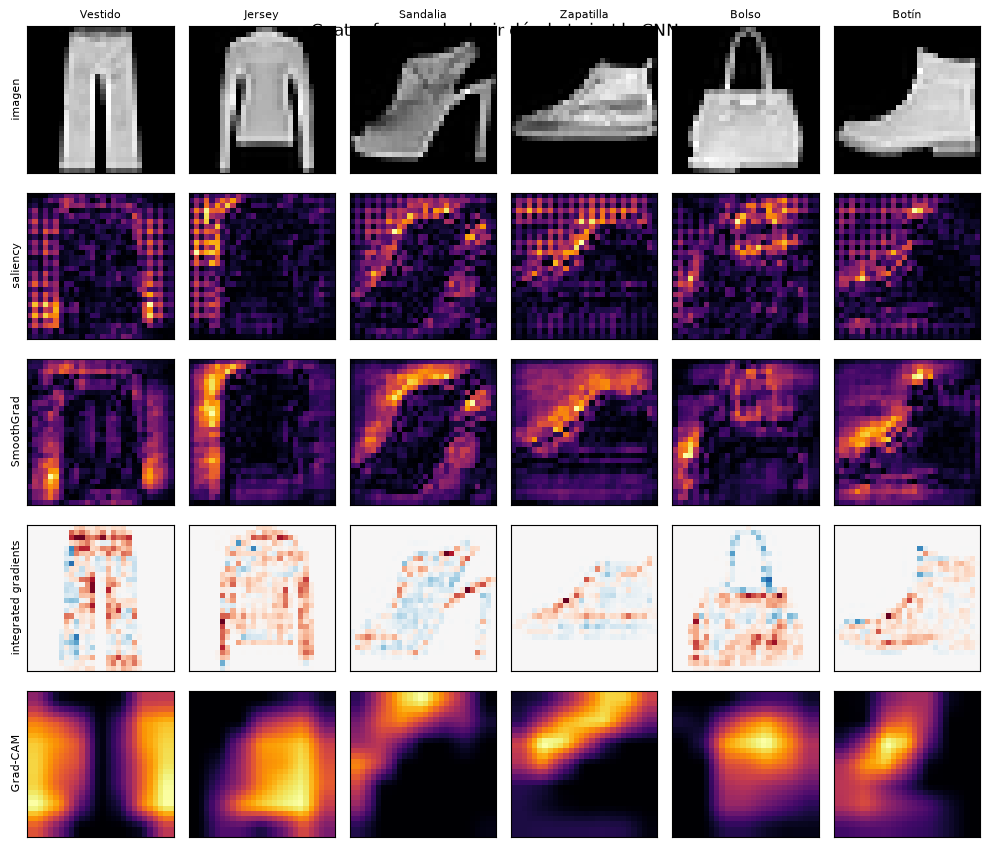

correlación de rangos media por imagen entre métodos (60 imágenes):
                      saliency  SmoothGrad  integrated gradients  Grad-CAM
saliency                  1.00        0.63                 -0.08      0.08
SmoothGrad                0.63        1.00                 -0.20      0.04
integrated gradients     -0.08       -0.20                  1.00     -0.02
Grad-CAM                  0.08        0.04                 -0.02      1.00


In [8]:
def _target_score(m, x, c): return m(x).gather(1, c[:, None]).sum()

def saliency_map(m, x, c):
    x = x.clone().requires_grad_(True); _target_score(m, x, c).backward(); return x.grad.detach()

def smoothgrad_map(m, x, c, n=25, sigma=0.15, seed=0):
    g = torch.Generator().manual_seed(seed); tot = torch.zeros_like(x)
    for _ in range(n): tot += saliency_map(m, x + sigma * torch.randn(x.shape, generator=g), c)
    return tot / n

def ig_map(m, x, c, steps=32, baseline=None):
    b = torch.zeros_like(x) if baseline is None else baseline; tot = torch.zeros_like(x)
    for k in range(steps): tot += saliency_map(m, b + (k + 0.5) / steps * (x - b), c)
    return tot / steps * (x - b)

def gradcam_map(m, x, c):
    A = m.features(x).detach().requires_grad_(True)
    m.fc(A.mean((2, 3))).gather(1, c[:, None]).sum().backward()
    w = A.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * A.detach()).sum(1, keepdim=True))
    return F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)

xs, ys = Xi_te[:200], yi_te[:200]
pred = cnn(xs).argmax(1)
# comprobación de completitud de los gradientes integrados en la CNN: sum(IG) debe ser f_c(x) - f_c(imagen negra)
ig_chk = ig_map(cnn, xs[:20], pred[:20], steps=64).sum((1, 2, 3))
with torch.no_grad(): ig_gap = (cnn(xs[:20]).gather(1, pred[:20, None])[:, 0] - cnn(torch.zeros_like(xs[:20])).gather(1, pred[:20, None])[:, 0])
print(f"completitud de IG en imágenes: máx |sum(IG) - (f(x) - f(negro))| = {(ig_chk - ig_gap).abs().max():.3f}  (las puntuaciones son de tamaño {ig_gap.abs().mean():.1f})")

maps = {"saliency": saliency_map(cnn, xs, pred).abs(), "SmoothGrad": smoothgrad_map(cnn, xs, pred).abs(),
        "integrated gradients": ig_map(cnn, xs, pred), "Grad-CAM": gradcam_map(cnn, xs, pred)}
show = [int(np.where(ys.numpy() == c)[0][0]) for c in [1, 2, 5, 7, 8, 9]]
fig, axes = plt.subplots(5, 6, figsize=(10, 9))
for j, i in enumerate(show):
    axes[0, j].imshow(xs[i, 0], cmap="gray"); axes[0, j].set_title(f"{FM_NAMES[pred[i]]}", fontsize=8)
    for r_, (name, mp) in enumerate(maps.items(), start=1):
        v = mp[i, 0].numpy(); lim = np.abs(v).max() + 1e-9
        axes[r_, j].imshow(v, cmap="RdBu_r" if name == "integrated gradients" else "inferno", vmin=-lim if name == "integrated gradients" else 0, vmax=lim)
        if j == 0: axes[r_, j].set_ylabel(name, fontsize=8)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel("imagen", fontsize=8); plt.suptitle("Cuatro formas de decir dónde 'mira' la CNN", y=0.93); plt.tight_layout(); plt.show()

# ¿coinciden los métodos entre sí? correlación de rangos media de |mapas| entre imágenes
names = list(maps); M = np.zeros((4, 4))
for a, b in itertools.product(range(4), range(4)):
    M[a, b] = np.mean([rank_corr(maps[names[a]][i].abs().flatten().numpy(), maps[names[b]][i].abs().flatten().numpy()) for i in range(60)])
print("correlación de rangos media por imagen entre métodos (60 imágenes):")
print(pd.DataFrame(M, index=names, columns=names).round(2).to_string())

**Lectura.** La CNN alcanza solo 0.742 de exactitud en prueba (8000 imágenes de entrenamiento, 7 épocas, una cabeza de pooling promedio global): suficiente para estudiar, no un modelo fuerte, y los modelos débiles dan mapas más ruidosos. Los gradientes integrados son completos en imágenes con un margen de 0.28 unidades de puntuación (puntuaciones de tamaño 8.6). Importa más la imagen que los números: los cuatro métodos producen mapas visiblemente distintos para la misma imagen y predicción. La correlación de rangos por imagen entre saliencia y SmoothGrad es 0.63 (el segundo es una versión suavizada de la primera), pero los gradientes integrados se correlacionan entre -0.08 y -0.20 con ellos y Grad-CAM entre 0.02 y 0.08 con todos. Parte de eso es por diseño (los gradientes integrados tienen signo y multiplican por la imagen; Grad-CAM es un mapa de 7 por 7 ampliado), pero muestra que "el mapa de atención del modelo" no es un único objeto. ¿Cuál creer? Las dos pruebas siguientes son la forma de decidirlo.

### 4.1 Prueba de cordura: ¿dependen los mapas del modelo?

Adebayo et al. ([2018](https://arxiv.org/abs/1810.03292)) propusieron una prueba que todo método de explicación debería superar: **aleatorizar los pesos del modelo y la explicación debería cambiar**. Si un método da casi la misma imagen para una red entrenada y para una red con pesos aleatorios, entonces la imagen nos habla de la *imagen de entrada* (bordes, contraste), no de lo que la red aprendió. Ellos aleatorizan capa por capa, desde arriba (la cabeza lineal) hasta la primera convolución ("aleatorización en cascada"). Medimos la correlación de rangos entre el mapa de cada método en el modelo entrenado y en el progresivamente destruido, y añadimos un **control sin modelo**: un detector de bordes de Sobel, que por construcción no puede depender de ningún modelo. Un método que se mantiene cerca del comportamiento del detector de bordes suspende la prueba.

                    saliency  integrated gradients  Grad-CAM
entrenada               1.00                  1.00      1.00
fc aleatoria            0.37                  0.88      0.08
+ c3 aleatoria          0.32                  0.88      0.05
+ c2 aleatoria          0.11                  0.87      0.08
+ todas aleatorias      0.03                  0.87      0.13


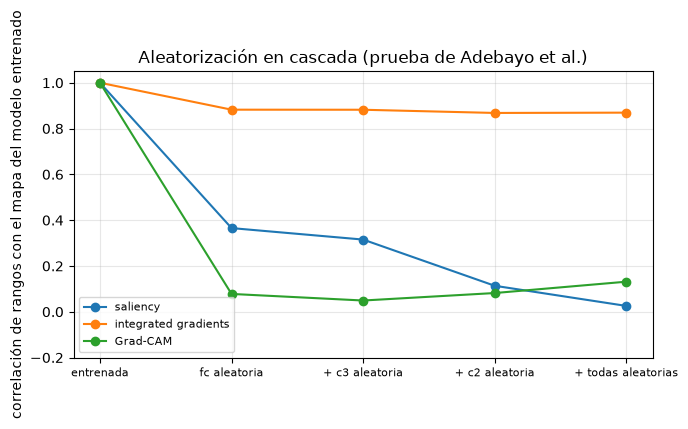

                      tras aleatorización completa  corr. con bordes de Sobel, entrenada  corr. con bordes de Sobel, aleatorizada
saliency                                      0.03                                 -0.07                                     0.20
integrated gradients                          0.87                                  0.55                                     0.54
Grad-CAM                                      0.13                                  0.01                                     0.10


exactitud de la red totalmente aleatorizada: 0.089 (el azar es 0.100)


In [9]:
import copy
from scipy import ndimage

def randomise(m, upto, seed=123):
    # reinicializa capas desde arriba: 'fc', luego también c3, c2, c1
    m2 = copy.deepcopy(m); order = ["fc", "c3", "c2", "c1"]; torch.manual_seed(seed)
    for name in order[:upto]:
        layer = getattr(m2, name); layer.reset_parameters()
    return m2.eval()

xs100, pred100 = xs[:100], pred[:100]
def edge_map(x):
    return torch.tensor(np.stack([np.hypot(ndimage.sobel(a[0], 0), ndimage.sobel(a[0], 1)) for a in x.numpy()]))[:, None]

methods = {"saliency": lambda m: saliency_map(m, xs100, pred100).abs(),
           "integrated gradients": lambda m: ig_map(m, xs100, pred100, steps=16).abs(),
           "Grad-CAM": lambda m: gradcam_map(m, xs100, pred100)}
orig = {k: f(cnn) for k, f in methods.items()}
stages = ["entrenada", "fc aleatoria", "+ c3 aleatoria", "+ c2 aleatoria", "+ todas aleatorias"]
res = {k: [1.0] for k in methods}
for upto in range(1, 5):
    mr = randomise(cnn, upto)
    for k, f in methods.items():
        mp = f(mr)
        res[k].append(np.mean([rank_corr(orig[k][i].flatten().numpy(), mp[i].flatten().numpy()) for i in range(100)]))
edges = edge_map(xs100)
edge_corr = {k: np.mean([rank_corr(orig[k][i].flatten().numpy(), edges[i].flatten().numpy()) for i in range(100)]) for k in methods}
# ¿cuánto se parecen los mapas de la red aleatorizada a un detector de bordes? (para saliencia e IG)
mr_all = randomise(cnn, 4)
edge_rand = {k: np.mean([rank_corr(f(mr_all)[i].flatten().numpy(), edges[i].flatten().numpy()) for i in range(100)]) for k, f in methods.items()}

print(pd.DataFrame(res, index=stages).round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 3.6))
for k in methods: ax.plot(stages, res[k], "o-", label=k)
ax.set_ylabel("correlación de rangos con el mapa del modelo entrenado"); ax.set_ylim(-0.2, 1.05); ax.tick_params(axis="x", labelsize=8)
ax.set_title("Aleatorización en cascada (prueba de Adebayo et al.)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(pd.DataFrame({"tras aleatorización completa": {k: res[k][-1] for k in methods},
                    "corr. con bordes de Sobel, entrenada": edge_corr, "corr. con bordes de Sobel, aleatorizada": edge_rand}).round(2).to_string())
print("exactitud de la red totalmente aleatorizada:", f"{accuracy(mr_all, Xi_te, yi_te):.3f}", "(el azar es 0.100)")

**Lectura.** La saliencia y Grad-CAM la superan: la saliencia cae a una correlación de 0.37 en cuanto solo se reinicializa la cabeza lineal, y a 0.03 cuando todas las capas son aleatorias; Grad-CAM baja a 0.08 en el primer paso y termina en 0.13. **Los gradientes integrados la suspenden en esta forma**: su correlación con su propia versión entrenada se queda en 0.88, 0.88, 0.87 y 0.87 mientras la red pasa de un 74 % de exactitud al azar (0.089). El mapa de una red aleatoria también tiene una correlación de rangos de 0.54 con un detector de bordes de Sobel, casi igual que la entrenada (0.55). Dos razones, ambas conocidas: los gradientes integrados multiplican el gradiente por la imagen (aquí con referencia negra), así que donde la imagen es cero el mapa es cero para cualquier red, y los muchos píxeles de fondo en cero coinciden trivialmente; y una red convolucional aleatoria sigue respondiendo a los bordes. Esto es exactamente lo que Adebayo et al. advirtieron para los métodos que multiplican por la entrada. No significa que los gradientes integrados sean inútiles (siguiente sección), solo que **su imagen por sí sola no muestra lo que la red aprendió**. Usamos 100 imágenes, una semilla de aleatorización y la correlación de rangos sobre todos los píxeles, la más burda de las medidas del artículo.

### 4.2 Fidelidad: borrar lo que señala el mapa

Un mapa es **fiel** si quitar los píxeles que clasifica más alto daña la predicción más que quitar píxeles al azar. La **curva de borrado** (Samek et al., [2017](https://arxiv.org/abs/1509.06321); Petsiuk et al., [2018](https://arxiv.org/abs/1806.07421)) pone en negro los $k$ píxeles principales para $k$ creciente y sigue la probabilidad de la clase predicha originalmente; un *área bajo la curva menor* significa un ranking más fiel. Añadimos dos controles honestos: el orden **aleatorio** (el suelo) y el **brillo** (borrar primero los píxeles más brillantes, un ranking sin modelo). Borrar poniendo píxeles en negro saca las imágenes de la distribución de entrenamiento, una debilidad conocida de esta prueba; volvemos a ello en la sección 9.

AUC de borrado (área bajo la curva de probabilidad frente a píxeles borrados, menor es más fiel):
integrated gradients    0.231
brillo (sin modelo)     0.388
Grad-CAM                0.584
SmoothGrad              0.611
saliency                0.617
random                  0.620


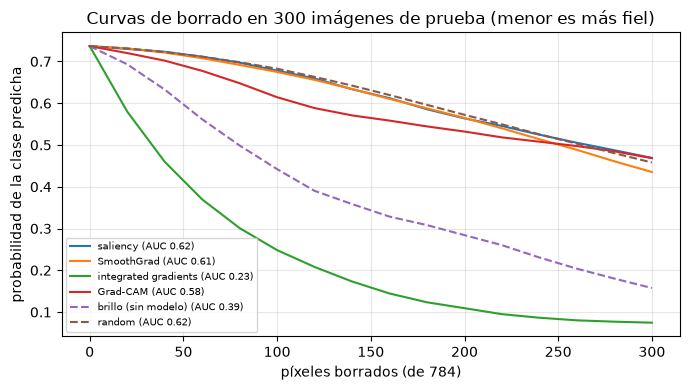

In [10]:
def deletion_curve(m, x, c, scores, ks):
    n = len(x); rank = scores.reshape(n, -1).argsort(1, descending=True); out = []
    for k in ks:
        xd = x.reshape(n, -1).clone(); xd.scatter_(1, rank[:, :k], 0.0)
        with torch.no_grad(): p = F.softmax(m(xd.reshape(x.shape)), 1).gather(1, c[:, None])[:, 0]
        out.append(float(p.mean()))
    return np.array(out)

ks = list(range(0, 301, 20))
xe, ce = Xi_te[:300], cnn(Xi_te[:300]).argmax(1)
scores = {"saliency": saliency_map(cnn, xe, ce).abs(), "SmoothGrad": smoothgrad_map(cnn, xe, ce).abs(),
          "integrated gradients": ig_map(cnn, xe, ce), "Grad-CAM": gradcam_map(cnn, xe, ce),
          "brillo (sin modelo)": xe.clone()}
g = torch.Generator().manual_seed(0)
curves = {k: deletion_curve(cnn, xe, ce, s, ks) for k, s in scores.items()}
curves["random"] = np.mean([deletion_curve(cnn, xe, ce, torch.rand(xe.shape, generator=g), ks) for _ in range(5)], 0)
auc = {k: np.trapezoid(v, ks) / ks[-1] for k, v in curves.items()}

print("AUC de borrado (área bajo la curva de probabilidad frente a píxeles borrados, menor es más fiel):")
print(pd.Series(auc).round(3).sort_values().to_string())
fig, ax = plt.subplots(figsize=(7, 4))
for k, v in curves.items(): ax.plot(ks, v, label=f"{k} (AUC {auc[k]:.2f})", ls="--" if k in ("random", "brillo (sin modelo)") else "-")
ax.set_xlabel("píxeles borrados (de 784)"); ax.set_ylabel("probabilidad de la clase predicha"); ax.legend(fontsize=7)
ax.set_title("Curvas de borrado en 300 imágenes de prueba (menor es más fiel)"); plt.tight_layout(); plt.show()

**Lectura.** Los gradientes integrados tienen con diferencia el área más baja (0.231), mejor que el ranking por brillo sin modelo (0.388). Grad-CAM (0.584) es algo mejor que el azar (0.620), y **la saliencia simple (0.617) y SmoothGrad (0.611) no son mejores que el azar** en esta prueba de borrado. Así que las dos pruebas discrepan: los gradientes integrados suspendieron la prueba de cordura pero son los más fieles por borrado, la saliencia pasó la prueba de cordura pero no es fiel por borrado. Superar una prueba no implica superar la otra, porque miden cosas distintas: la sensibilidad de la salida a cambios pequeños (gradientes, que se saturan en redes con unidades ReLU y una cabeza con pooling) frente al efecto de quitar evidencia (que los gradientes integrados, por su camino del negro a la imagen, están construidos para seguir). Parte de la ventaja de los gradientes integrados es que clasifican primero los píxeles brillantes que contribuyen positivamente, y quitarlos también es una perturbación fuerte; el control por brillo muestra hasta dónde llega ya un ranking sin modelo. 300 imágenes de prueba y un modelo; las diferencias por debajo de 0.02 no deben interpretarse.

## 5. Un atajo plantado: ¿puede la atribución encontrarlo?

La depuración es el uso más práctico de la interpretabilidad, así que la probamos con un defecto que creamos. Plantamos una **marca de agua**: un parche de $4 \times 4$ en la esquina superior izquierda (16 de 784 píxeles, el 2 % de la imagen) cuyo nivel de gris **codifica la clase**. En el conjunto de entrenamiento el parche está siempre presente y siempre es correcto, un atajo perfecto que además es *más fácil* de aprender que la forma de un abrigo. Versiones reales de esto son comunes: la marca de un escáner de hospital, una marca de agua en las fotografías de una clase, un color de fondo que va con una etiqueta.

Entrenamos un modelo con los datos con marca de agua y lo probamos de tres maneras: con la marca de agua como en el entrenamiento (**señal activa**), con el parche borrado (**señal quitada**) y con el parche mostrando una clase *equivocada* (**señal engañosa**). El modelo "limpio" de la sección 4 nunca vio la marca de agua y sirve de control. Un tercer modelo se entrena con el parche presente pero **aleatorio** (descorrelacionado de la clase), el remedio estándar. Para ver si la atribución revela el defecto medimos (i) la **proporción de masa de atribución** dentro del parche (un reparto justo sería el 2 %) y (ii) el **juego del señalamiento** (Zhang et al., [2018](https://arxiv.org/abs/1608.00507)): el porcentaje de imágenes en que el píxel con mayor atribución cae dentro del parche.

entrenados el modelo con atajo y el remedio en 14 s


                                         model  señal on  señal off  señal wrong
modelo limpio (sin parche en el entrenamiento)     0.678      0.743        0.698
          modelo con atajo (parche = etiqueta)     0.880      0.552        0.582
              remedio (el parche es aleatorio)     0.754      0.768        0.762



gradientes integrados en imágenes de prueba con marca de agua (un reparto justo de masa sería 0.02):
                                                    clean  shortcut  remedy
proporción de masa de |IG| en el parche             0.047     0.136   0.037
juego del señalamiento (píxel máximo en el parche)  0.023     0.453   0.017


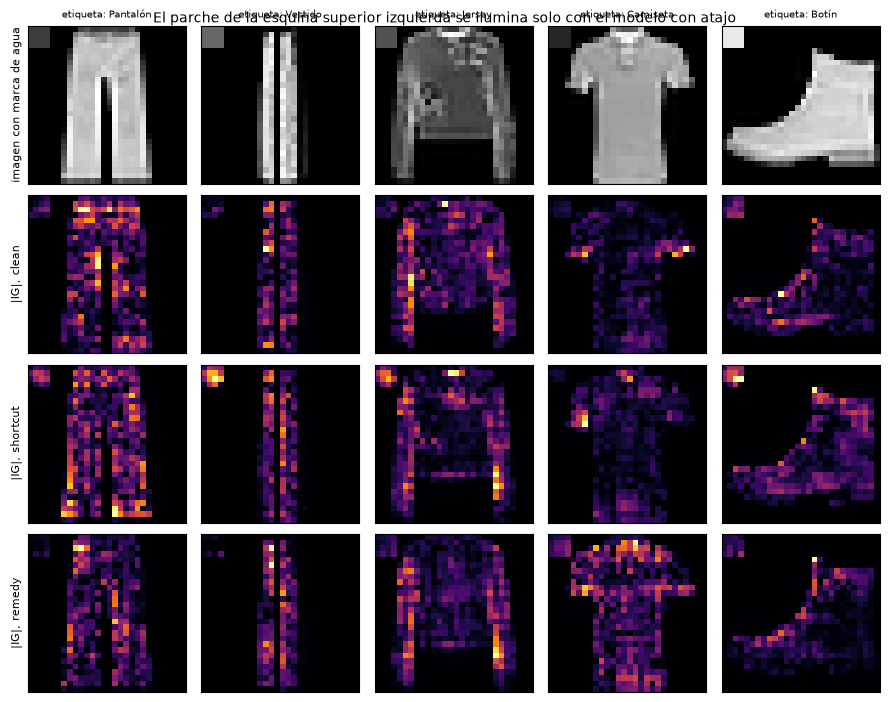

In [11]:
def cue_levels(y): return 0.15 + 0.085 * y.float()                  # nivel de gris que codifica la clase
def with_cue(x, y, mode, seed=0):
    x = x.clone(); g = torch.Generator().manual_seed(seed)
    if mode == "off": lvl = torch.zeros(len(x))
    elif mode == "on": lvl = cue_levels(y)
    elif mode == "wrong": lvl = cue_levels((y + torch.randint(1, 10, (len(y),), generator=g)) % 10)
    elif mode == "random": lvl = cue_levels(torch.randint(0, 10, (len(y),), generator=g))
    x[:, 0, :4, :4] = lvl[:, None, None]
    return x

t0 = time.time()
cue_model = train_cnn(with_cue(Xi_tr, yi_tr, "on"), yi_tr, seed=1)
fixed_model = train_cnn(with_cue(Xi_tr, yi_tr, "random", seed=7), yi_tr, seed=2)
print(f"entrenados el modelo con atajo y el remedio en {time.time() - t0:.0f} s")

rows = []
for name, m in [("modelo limpio (sin parche en el entrenamiento)", cnn), ("modelo con atajo (parche = etiqueta)", cue_model), ("remedio (el parche es aleatorio)", fixed_model)]:
    rows.append({"model": name, **{f"señal {mode}": accuracy(m, with_cue(Xi_te, yi_te, mode), yi_te) for mode in ["on", "off", "wrong"]}})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# atribución: ¿dónde pone su masa el gradiente integrado en los tres modelos, en las imágenes de prueba con 'señal activa'?
xc, yc = with_cue(Xi_te[:300], yi_te[:300], "on"), yi_te[:300]
def patch_stats(m):
    p = m(xc).argmax(1); a = ig_map(m, xc, p, steps=16).abs()[:, 0]
    mass = a[:, :4, :4].sum((1, 2)) / a.sum((1, 2)); top = a.flatten(1).argmax(1); inside = ((top // 28) < 4) & ((top % 28) < 4)
    return float(mass.mean()), float(inside.float().mean()), a
stats = {n: patch_stats(m) for n, m in [("clean", cnn), ("shortcut", cue_model), ("remedy", fixed_model)]}
print("\ngradientes integrados en imágenes de prueba con marca de agua (un reparto justo de masa sería 0.02):")
print(pd.DataFrame({n: {"proporción de masa de |IG| en el parche": s[0], "juego del señalamiento (píxel máximo en el parche)": s[1]} for n, s in stats.items()}).round(3).to_string())

fig, axes = plt.subplots(4, 5, figsize=(9, 7.4))
for j, i in enumerate([0, 3, 5, 8, 11]):
    axes[0, j].imshow(xc[i, 0], cmap="gray"); axes[0, j].set_title(f"etiqueta: {FM_NAMES[yc[i]]}", fontsize=7)
    for r_, n in enumerate(["clean", "shortcut", "remedy"], start=1):
        axes[r_, j].imshow(stats[n][2][i], cmap="inferno")
        if j == 0: axes[r_, j].set_ylabel(f"|IG|, {n}", fontsize=8)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel("imagen con marca de agua", fontsize=8); plt.suptitle("El parche de la esquina superior izquierda se ilumina solo con el modelo con atajo", y=0.94, fontsize=10); plt.tight_layout(); plt.show()

**Lectura.** El atajo funcionó como se diseñó. En las imágenes de prueba con marca de agua el modelo con atajo obtiene 0.880, más que el modelo limpio (0.678, que nunca vio el parche). Cuando se borra el parche su exactitud cae 33 puntos hasta 0.552, y cuando el parche muestra la clase equivocada cae a 0.582: usa la esquina además de la prenda, porque 0.55 sigue muy por encima del azar. Al modelo limpio apenas le importa (0.678, 0.743, 0.698, dentro del ruido de un único modelo en 1000 imágenes) y el remedio, entrenado con un parche aleatorio, es plano en las tres condiciones (0.754, 0.768, 0.762), como debe ser un modelo obligado a ignorar el parche. La atribución encontró el defecto: para el modelo con atajo el píxel de mayor gradiente integrado cae en el parche de 4 por 4 en el 45 % de las imágenes de prueba (el 2 % de los píxeles), frente al 2 % del modelo limpio y el 2 % del remedio; el parche concentra el 13.6 % de la masa de atribución frente al 4.7 % y el 3.7 %. Dos cautelas. La atribución dijo "el parche importa", no "el parche es una trampa"; decidirlo necesitó nuestro conocimiento de cómo se hicieron los datos, y quitar la señal para medir la caída de exactitud es la evidencia real. Y el juego del señalamiento lo encontró en menos de la mitad de las imágenes, porque el modelo también usa la prenda: la ausencia de un punto brillante no habría demostrado la ausencia de un atajo. Una semilla por modelo.

## 6. Grad-CAM en una ResNet-18 preentrenada

Entrenar una red grande desde cero queda fuera del alcance de una CPU, así que para un modelo real usamos la **ResNet-18** entrenada con ImageNet de He et al. ([2015](https://arxiv.org/abs/1512.03385)) de `torchvision` (pesos `IMAGENET1K_V1`, en caché; el código tiene licencia BSD-3 y los pesos se entrenaron con ImageNet, cuyas [condiciones](https://www.image-net.org/download.php) restringen el uso a investigación y educación no comerciales; [documentación del modelo](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)). Grad-CAM usa la última etapa residual (`layer4`, una rejilla de 7 por 7). Las fotografías vienen incluidas con scikit-image ([documentación](https://scikit-image.org/docs/stable/api/skimage.data.html); el gato y la taza de café son CC0, el astronauta y el cohete son imágenes de la NASA de dominio público). Tomamos cuatro fotografías, tres recortes de cada una (12 imágenes), y hacemos una **prueba de borrado con parches de $14 \times 14$ píxeles** (una rejilla de $16 \times 16$), comparando Grad-CAM con la saliencia simple y con parches aleatorios. El juguete difiere de la práctica en la escala: una red pequeña y una docena de imágenes, suficiente para ver el método funcionar pero no para ordenar métodos en general.

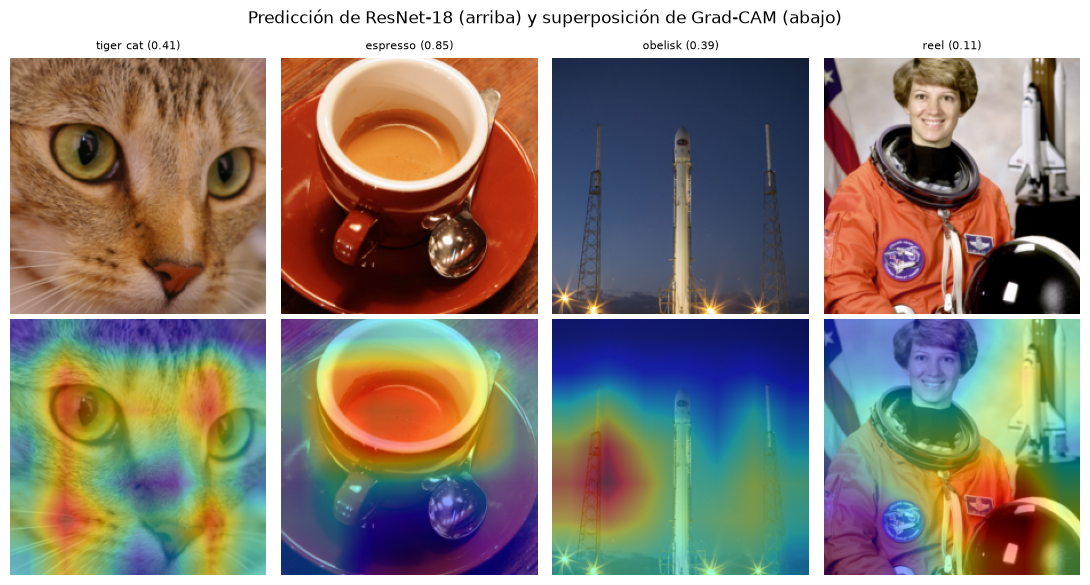

Predicciones de ResNet-18: ['tiger cat (0.41)', 'Egyptian cat (0.44)', 'Egyptian cat (0.68)', 'espresso (0.85)', 'espresso (0.86)', 'espresso (0.81)', 'obelisk (0.39)', 'obelisk (0.42)', 'missile (0.36)', 'reel (0.11)', 'stethoscope (0.36)', 'stethoscope (0.17)']
AUC de borrado: {'Grad-CAM': 0.162, 'saliency': 0.135, 'random': 0.121}
probabilidad de la clase predicha tras borrar 96 parches (37 %): {'Grad-CAM': 0.043, 'saliency': 0.023, 'random': 0.001}


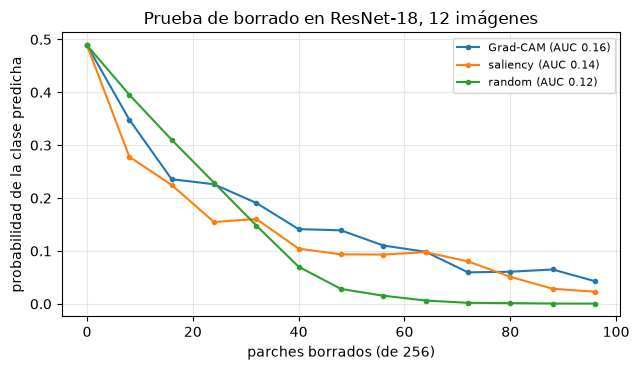

In [12]:
import torchvision
from skimage import data as skdata

W = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
rn = torchvision.models.resnet18(weights=W).eval()
CATS = W.meta["categories"]
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def crops(img, n=3, seed=0):
    im = Image.fromarray(img); w, h = im.size; s = 256 / min(w, h)
    im = np.array(im.resize((round(w * s), round(h * s)), Image.BILINEAR)); H_, W_ = im.shape[:2]
    r = np.random.default_rng(seed); out = [im[(H_ - 224) // 2:(H_ - 224) // 2 + 224, (W_ - 224) // 2:(W_ - 224) // 2 + 224]]
    for _ in range(n - 1):
        y0, x0 = r.integers(0, H_ - 223), r.integers(0, W_ - 223); out.append(im[y0:y0 + 224, x0:x0 + 224])
    return out
photos = {"chelsea": skdata.chelsea(), "coffee": skdata.coffee(), "rocket": skdata.rocket(), "astronaut": skdata.astronaut()}
raw = [c for k, v in photos.items() for c in crops(v, 3, seed=len(k))]
xr = (torch.from_numpy(np.stack(raw)).permute(0, 3, 1, 2).float() / 255 - MEAN) / STD

def resnet_cam(x, c=None):
    store = {}; h = rn.layer4.register_forward_hook(lambda m, i, o: store.__setitem__("A", o))
    logits = rn(x); h.remove(); A = store["A"]
    c = logits.argmax(1) if c is None else c
    g = torch.autograd.grad(logits.gather(1, c[:, None]).sum(), A)[0]
    cam = F.relu((g.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True)).detach()
    return F.interpolate(cam, size=224, mode="bilinear", align_corners=False)[:, 0], c, F.softmax(logits, 1).detach()

def resnet_saliency(x, c):
    x = x.clone().requires_grad_(True); rn(x).gather(1, c[:, None]).sum().backward(); return x.grad.abs().amax(1)

cam, cls, probs = resnet_cam(xr)
sal = resnet_saliency(xr, cls)
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for j, i in enumerate([0, 3, 6, 9]):
    axes[0, j].imshow(raw[i]); axes[0, j].set_title(f"{CATS[cls[i]]} ({probs[i, cls[i]]:.2f})", fontsize=8)
    axes[1, j].imshow(raw[i]); axes[1, j].imshow(cam[i], cmap="jet", alpha=0.45)
for a in axes.ravel(): a.axis("off"); a.grid(False)
plt.suptitle("Predicción de ResNet-18 (arriba) y superposición de Grad-CAM (abajo)"); plt.tight_layout(); plt.show()

def patch_scores(m):                                         # media de un mapa (n,224,224) en cada parche de 14x14 -> (n, 256)
    return F.avg_pool2d(m[:, None], 14).flatten(1)

def patch_deletion(x, c, pscore, ks):
    rank = pscore.argsort(1, descending=True); out = []
    for k in ks:
        keep = torch.ones(len(x), 256); keep.scatter_(1, rank[:, :k], 0.0)
        mask = F.interpolate(keep.view(-1, 1, 16, 16), size=224, mode="nearest")
        with torch.no_grad(): p = F.softmax(rn(x * mask), 1).gather(1, c[:, None])[:, 0]       # los parches borrados pasan a ser el color medio
        out.append(float(p.mean()))
    return np.array(out)

ksr = list(range(0, 97, 8)); gr = torch.Generator().manual_seed(0)
rc = {"Grad-CAM": patch_deletion(xr, cls, patch_scores(cam), ksr), "saliency": patch_deletion(xr, cls, patch_scores(sal), ksr),
      "random": np.mean([patch_deletion(xr, cls, torch.rand(len(xr), 256, generator=gr), ksr) for _ in range(5)], 0)}
print("Predicciones de ResNet-18:", [f"{CATS[int(c)]} ({float(probs[i, int(c)]):.2f})" for i, c in enumerate(cls)])
print("AUC de borrado:", {k: round(float(np.trapezoid(v, ksr) / ksr[-1]), 3) for k, v in rc.items()})
print("probabilidad de la clase predicha tras borrar 96 parches (37 %):", {k: round(float(v[-1]), 3) for k, v in rc.items()})
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for k, v in rc.items(): ax.plot(ksr, v, "o-", ms=3, label=f"{k} (AUC {np.trapezoid(v, ksr) / ksr[-1]:.2f})")
ax.set_xlabel("parches borrados (de 256)"); ax.set_ylabel("probabilidad de la clase predicha"); ax.legend(fontsize=8)
ax.set_title("Prueba de borrado en ResNet-18, 12 imágenes"); plt.tight_layout(); plt.show()

**Lectura.** Las predicciones son plausibles para el gato (tiger cat 0.41 y Egyptian cat 0.44 y 0.68) y el café (espresso, de 0.81 a 0.86), parcialmente correctas para el cohete (obelisk 0.39 y 0.42, missile 0.36, reel 0.11) y erróneas para el astronauta (stethoscope 0.36 y 0.17; ImageNet no tiene la clase "astronauta" y el modelo tiene que decir algo); la figura muestra dónde cree Grad-CAM que está la evidencia. La prueba de borrado **no** confirma a Grad-CAM aquí: su área es 0.162, la de la saliencia 0.135 y la del azar 0.121, así que los parches aleatorios son los que más dañan la predicción (tras borrar 96 de 256 parches la probabilidad es 0.043 para Grad-CAM, 0.023 para la saliencia y 0.001 para el azar). Una razón plausible, que no probamos, es que el borrado aleatorio reparte bloques grises por toda la imagen y rompe las texturas en que se apoya la red, mientras que Grad-CAM borra una región contigua y el contexto restante sigue sosteniendo la clase; otra es que la rejilla de 7 por 7 de Grad-CAM es gruesa frente a un parche de 14 píxeles. Doce imágenes de cuatro fotografías son muy pocas para ordenar métodos, pero bastan para mostrar que un mapa de calor convincente y un ranking fiel son propiedades distintas. El juguete difiere de la práctica en la escala: en la práctica se evalúa con miles de imágenes, varias capas de la red y distintas estrategias de relleno.

## 7. Modelos de lenguaje: sondas y la atención no es explicación

Para texto usamos **DistilBERT** (Sanh et al., [2019](https://arxiv.org/abs/1910.01108); [ficha del modelo](https://huggingface.co/distilbert/distilbert-base-uncased), Apache 2.0), un codificador de 66 millones de parámetros con 6 capas transformer, en caché desde el Hugging Face Hub, y **Banking77** (Casanueva et al., [2020](https://arxiv.org/abs/2003.04807); [ficha del dataset](https://huggingface.co/datasets/PolyAI/banking77), CC BY 4.0): preguntas cortas de clientes etiquetadas con una intención. Conservamos 8 intenciones elegidas al azar, 40 preguntas de entrenamiento y 25 de prueba por cada una. El modelo de lenguaje del módulo 10 de Neural Networks 1001 se entrena desde cero y es demasiado pequeño para tener semántica real; DistilBERT es lo auténtico, en un tamaño que una CPU soporta.

### 7.1 Sondas lineales

Una **sonda** es un clasificador simple entrenado sobre los estados ocultos congelados de un modelo para comprobar **qué información es legible linealmente** a cada profundidad. Sondeamos la media de los vectores de los tokens en cada una de las 7 paradas (la capa de embeddings y las 6 capas transformer). Una sonda solo muestra que la información está *presente*, no que el modelo la *use*. Hewitt y Liang ([2019](https://arxiv.org/abs/1909.03368)) advierten de que una sonda con suficiente capacidad puede aprender la tarea por sí sola, así que añadimos una **tarea de control**: etiquetas que dependen de una función aleatoria de una palabra, que ninguna representación "conoce" pero que una sonda de 768 dimensiones con 320 ejemplos podría memorizar.

intenciones: ['apple_pay_or_google_pay', 'card_acceptance', 'exchange_via_app', 'fiat_currency_support', 'supported_cards_and_currencies', 'topping_up_by_card', 'verify_my_identity', 'visa_or_mastercard']
ejemplos: google pay top up did not work | Do I get  a mastercard and visa?


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 11660.24it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


estados ocultos extraídos en 6 s: entrenamiento (320, 7, 768), prueba (200, 7, 768)


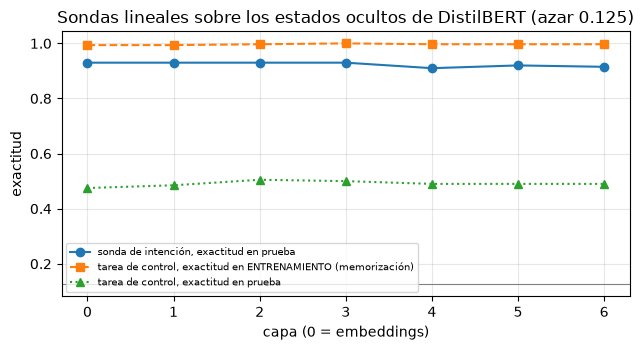

 layer  intent_test  control_train  control_test
     0        0.930          0.994         0.475
     1        0.930          0.994         0.485
     2        0.930          0.997         0.505
     3        0.930          1.000         0.500
     4        0.910          0.997         0.490
     5        0.920          0.997         0.490
     6        0.915          0.997         0.490


In [13]:
from transformers import AutoTokenizer, AutoModel
from huggingface_hub import DatasetCard
from sklearn.preprocessing import StandardScaler

tr_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/train-00000-of-00001.parquet", repo_type="dataset"))
te_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/test-00000-of-00001.parquet", repo_type="dataset"))
try:
    _nm = DatasetCard.load("PolyAI/banking77").data.to_dict()["dataset_info"]["features"][1]["dtype"]["class_label"]["names"]
    ALL_NAMES = list(_nm.values()) if isinstance(_nm, dict) else list(_nm)
    assert len(ALL_NAMES) == 77
except Exception:
    ALL_NAMES = [f"intención {i}" for i in range(77)]
rng = np.random.default_rng(1)
CLS = sorted(rng.choice(77, size=8, replace=False).tolist())
def take(df, per):
    parts = [df[df.label == c].sample(per, random_state=0) for c in CLS]
    d = pd.concat(parts).reset_index(drop=True); d["y"] = d.label.map({c: i for i, c in enumerate(CLS)}); return d
trb, teb = take(tr_b, 40), take(te_b, 25)
print("intenciones:", [ALL_NAMES[c] for c in CLS]); print("ejemplos:", trb.text.iloc[0], "|", trb.text.iloc[-1])

tok = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert/distilbert-base-uncased", attn_implementation="eager").eval()

@torch.no_grad()
def layer_means(texts, bs=64):
    outs = []
    for i in range(0, len(texts), bs):
        b = tok(texts[i:i + bs], return_tensors="pt", padding=True)
        hs = bert(**b, output_hidden_states=True).hidden_states               # 7 tensores (n, T, 768)
        m = b["attention_mask"][..., None].float()
        outs.append(torch.stack([(h * m).sum(1) / m.sum(1) for h in hs], 1))   # (n, 7, 768)
    return torch.cat(outs).numpy()
t0 = time.time()
Htr, Hte = layer_means(trb.text.tolist()), layer_means(teb.text.tolist())
print(f"estados ocultos extraídos en {time.time() - t0:.0f} s: entrenamiento {Htr.shape}, prueba {Hte.shape}")

def word_label(text, seed=0):      # tarea de control: una clase aleatoria fija para la palabra más larga de la frase
    w = max(text.lower().split(), key=len); return int(np.random.default_rng(sum(map(ord, w)) + seed).integers(0, 8))
ctl_tr, ctl_te = np.array([word_label(t) for t in trb.text]), np.array([word_label(t) for t in teb.text])
rows = []
for l in range(7):
    sc = StandardScaler().fit(Htr[:, l])
    real = LogisticRegression(max_iter=500, C=0.05).fit(sc.transform(Htr[:, l]), trb.y)
    ctl = LogisticRegression(max_iter=500, C=0.05).fit(sc.transform(Htr[:, l]), ctl_tr)
    rows.append(dict(layer=l, intent_test=real.score(sc.transform(Hte[:, l]), teb.y), control_train=ctl.score(sc.transform(Htr[:, l]), ctl_tr),
                     control_test=ctl.score(sc.transform(Hte[:, l]), ctl_te)))
P = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(P.layer, P.intent_test, "o-", label="sonda de intención, exactitud en prueba"); ax.plot(P.layer, P.control_train, "s--", label="tarea de control, exactitud en ENTRENAMIENTO (memorización)")
ax.plot(P.layer, P.control_test, "^:", label="tarea de control, exactitud en prueba"); ax.axhline(1 / 8, color="grey", lw=0.8)
ax.set_xlabel("capa (0 = embeddings)"); ax.set_ylabel("exactitud"); ax.legend(fontsize=7); ax.set_title("Sondas lineales sobre los estados ocultos de DistilBERT (azar 0.125)"); plt.tight_layout(); plt.show()
print(P.round(3).to_string(index=False))

**Lectura.** Una sonda lineal en cualquiera de las siete paradas identifica la intención de una pregunta nueva con una exactitud de 0.91 a 0.93, siendo el azar 0.125, y **la capa de embeddings por sí sola ya es tan buena como las capas posteriores** (0.930 en las capas 0 a 3, de 0.910 a 0.920 en las capas 4 a 6, una diferencia de tres o cuatro frases de prueba de 200). Las ocho intenciones se distinguen por palabras clave ("visa", "identity", "exchange"), que la media de los embeddings de palabras ya capta, así que esta tarea no puede decirnos en qué parte de la red aparece la información. La tarea de control muestra por qué las sondas requieren cuidado: con solo 320 ejemplos de entrenamiento una sonda de 768 dimensiones memoriza las etiquetas aleatorias (exactitud de entrenamiento de 0.99 a 1.00 en todas las capas), y su exactitud de prueba de 0.48 a 0.51 está muy por encima del azar porque las mismas palabras largas se repiten en las frases de prueba, así que incluso el control es en parte aprendible a partir de la identidad de las palabras. Una sonda muestra que la información es **legible linealmente**, no que el modelo la use, ni en qué capa se creó.

### 7.2 La atención no es explicación

Los pesos de atención de un transformer son fáciles de leer y parecen una explicación: "el modelo atendió a estas palabras". Jain y Wallace ([2019](https://arxiv.org/abs/1902.10186)) mostraron que los pesos de atención a menudo se correlacionan débilmente con la importancia basada en gradientes y que atenciones muy distintas pueden dar la misma salida (Wiegreffe y Pinter, [2019](https://arxiv.org/abs/1908.04626), sostienen que la cuestión es más sutil; vale la pena leer ambos artículos). Aquí lo medimos. El clasificador es la regresión logística sobre la **media de la última capa** de 7.1, de modo que todo el camino de las palabras a una decisión es una función derivable. Para 40 preguntas de prueba calculamos tres puntuaciones de importancia para cada trozo de palabra:

* **atención**: la atención de la última capa, promediada sobre las 12 cabezas y sobre las posiciones de consulta (cuánta atención recibe el token);
* **gradiente por entrada**: el valor absoluto del gradiente de la puntuación de la clase predicha respecto al embedding del token, por el embedding, sumado sobre las dimensiones;
* **oclusión**: se sustituye el token por `[MASK]` y se mide la caída de la probabilidad de la clase predicha, lo más parecido a una medición causal directa que tenemos aquí.

Luego **borramos** el token mejor clasificado según cada puntuación (sustituyéndolo por `[MASK]`) y medimos la caída de la probabilidad de la clase predicha; el borrado aleatorio es el control.

el clasificador sobre la última capa: exactitud en prueba 0.915


40 frases analizadas en 20 s; probabilidad media de la clase predicha: 0.94

correlación de rangos media entre puntuaciones de importancia (por frase, sobre tokens reales):
atención vs gradiente x entrada    -0.15
atención vs oclusión                0.04
atención desde [CLS] vs oclusión   -0.23
gradiente x entrada vs oclusión     0.39

caída media de la probabilidad al sustituir por [MASK] el token mejor clasificado:
oclusión                  0.135
gradiente x entrada       0.115
atención (última capa)    0.008
random                   -0.002
atención desde [CLS]     -0.008


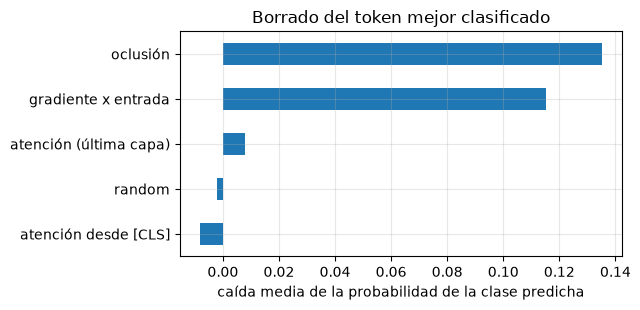

In [14]:
sc7 = StandardScaler().fit(Htr[:, 6])
clf7 = LogisticRegression(max_iter=500, C=0.05).fit(sc7.transform(Htr[:, 6]), trb.y)
Wc, bc = torch.tensor(clf7.coef_, dtype=torch.float32), torch.tensor(clf7.intercept_, dtype=torch.float32)
mu, sg = torch.tensor(sc7.mean_, dtype=torch.float32), torch.tensor(sc7.scale_, dtype=torch.float32)
print(f"el clasificador sobre la última capa: exactitud en prueba {clf7.score(sc7.transform(Hte[:, 6]), teb.y):.3f}")

def run(ids, mask, embeds=None, attn=False):
    emb = bert.embeddings.word_embeddings(ids) if embeds is None else embeds
    out = bert(inputs_embeds=emb, attention_mask=mask, output_attentions=attn)
    m = mask[..., None].float(); pooled = (out.last_hidden_state * m).sum(1) / m.sum(1)
    return ((pooled - mu) / sg) @ Wc.T + bc, out, emb

special = {tok.cls_token_id, tok.sep_token_id}
res_rows = []; per_sentence = []
t0 = time.time()
for text in teb.text.tolist()[:40]:
    b = tok(text, return_tensors="pt"); ids, mask = b["input_ids"], b["attention_mask"]
    real = [j for j in range(ids.shape[1]) if int(ids[0, j]) not in special]
    if len(real) < 4: continue
    emb = bert.embeddings.word_embeddings(ids).detach().requires_grad_(True)
    logits, out, _ = run(ids, mask, embeds=emb, attn=True)
    c = int(logits.argmax()); p0 = float(F.softmax(logits, 1)[0, c]); logits[0, c].backward()
    gi = (emb.grad * emb).abs().sum(-1)[0].detach().numpy()
    att = out.attentions[-1][0].mean(0).detach()                          # (T, T) promediado sobre las cabezas
    ai = att.mean(0).numpy()                                              # atención RECIBIDA, promediada sobre las consultas
    cls_row = att[0].numpy()                                              # atención DESDE [CLS]
    occ = np.zeros(ids.shape[1])
    with torch.no_grad():
        for j in real:
            i2 = ids.clone(); i2[0, j] = tok.mask_token_id
            occ[j] = p0 - float(F.softmax(run(i2, mask)[0], 1)[0, c])
    sc_ = {"atención (última capa)": ai, "atención desde [CLS]": cls_row, "gradiente x entrada": gi, "oclusión": occ}
    drop = {}
    r_ = np.random.default_rng(len(per_sentence))
    for name, v in {**sc_, "random": r_.random(ids.shape[1])}.items():
        top = real[int(np.argmax([v[j] for j in real]))]; i2 = ids.clone(); i2[0, top] = tok.mask_token_id
        with torch.no_grad(): drop[name] = p0 - float(F.softmax(run(i2, mask)[0], 1)[0, c])
    per_sentence.append(dict(
        corr_att_grad=rank_corr(ai[real], gi[real]), corr_att_occ=rank_corr(ai[real], occ[real]), corr_grad_occ=rank_corr(gi[real], occ[real]),
        corr_cls_occ=rank_corr(cls_row[real], occ[real]), p0=p0, **{f"drop_{k}": v for k, v in drop.items()}))
S = pd.DataFrame(per_sentence)
print(f"{len(S)} frases analizadas en {time.time() - t0:.0f} s; probabilidad media de la clase predicha: {S.p0.mean():.2f}")
print("\ncorrelación de rangos media entre puntuaciones de importancia (por frase, sobre tokens reales):")
print(pd.Series({"atención vs gradiente x entrada": S.corr_att_grad.mean(), "atención vs oclusión": S.corr_att_occ.mean(),
                 "atención desde [CLS] vs oclusión": S.corr_cls_occ.mean(), "gradiente x entrada vs oclusión": S.corr_grad_occ.mean()}).round(2).to_string())
D = S[[c for c in S if c.startswith("drop_")]].mean().rename(lambda s: s[5:])
print("\ncaída media de la probabilidad al sustituir por [MASK] el token mejor clasificado:")
print(D.round(3).sort_values(ascending=False).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.2)); D.sort_values().plot.barh(ax=ax, color="tab:blue"); ax.set_xlabel("caída media de la probabilidad de la clase predicha")
ax.set_title("Borrado del token mejor clasificado"); plt.tight_layout(); plt.show()

**Lectura.** La atención no sigue lo que importa para la decisión. En 40 frases de prueba (el clasificador tiene una confianza media del 94 %) la correlación de rangos entre la atención de la última capa y la importancia por gradiente por entrada es -0.15, con la oclusión 0.04, y la atención desde el token `[CLS]` es -0.23 con la oclusión; en cambio el gradiente y la oclusión coinciden en 0.39. Cuando el token mejor clasificado se sustituye por `[MASK]`, el ranking por oclusión (que elige el mejor token individual por construcción, así que es una cota superior) reduce la probabilidad de la clase predicha en 0.135 de media, el gradiente por entrada en 0.115, la atención de la última capa en 0.008 y la atención de `[CLS]` en -0.008, sin diferencia respecto al azar (-0.002). Así que, al menos en este modelo y capa, los tokens que reciben atención no son los tokens de los que depende la decisión. Probamos una capa, promediada sobre las cabezas, en un modelo cuya salida pasa por un pooling promedio, así que esto es una medición y no un teorema general: Wiegreffe y Pinter sostienen que la atención aún puede ser una explicación útil bajo otras definiciones, y los ejercicios te piden probar la primera capa. Lo que el resultado sí muestra es que "mira los pesos de atención" no es un método en el que se pueda confiar sin una prueba exactamente como esta.

## 8. Interpretabilidad mecanicista: circuitos y características

La **interpretabilidad mecanicista** intenta hacer ingeniería inversa de una red hasta partes a las que podamos poner nombre: **circuitos** (pequeños subgrafos de cabezas y neuronas que implementan un algoritmo) y **características** (direcciones del espacio de activaciones que significan algo). Dos ideas son centrales, y demostramos ambas con juguetes porque hacerlo en un modelo de lenguaje grande es un programa de investigación, no un notebook.

* El **parcheo de activaciones** (también *trazado causal*): se ejecuta el modelo con una entrada *limpia* y con una entrada *corrompida* que difiere en un hecho. Se copia la activación de un componente de la ejecución limpia a la corrompida. Si vuelve el comportamiento limpio, ese componente lleva la información. Es una **intervención**, así que permite afirmaciones causales que la simple atribución no permite.
* Las **cabezas de inducción** (Olsson et al., [2022](https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html)): un circuito de dos capas que completa patrones de la forma `[A][B] ... [A] -> [B]`. Una **cabeza de token previo** en la capa 0 escribe "mi token anterior era A" en la posición siguiente; una **cabeza de inducción** en la capa 1 lo usa para atender al token que *sigue* a la aparición anterior del token actual y lo copia. Olsson et al. sostienen que estas cabezas son una parte importante del aprendizaje en contexto de los transformers.

### 8.1 Un juguete que aprende una cabeza de inducción

Entrenamos un transformer diminuto **solo de atención** (2 capas, 4 cabezas por capa, ancho 64, sin MLP) con secuencias aleatorias de tokens (24 símbolos) de longitud 24 en las que un bloque aleatorio de 5 a 11 tokens se **repite** más adelante. Predecir el primer bloque es imposible; predecir su repetición requiere copiar en contexto. Como la longitud del bloque varía, un atajo basado en la posición no puede resolverlo. El juguete difiere de los modelos de lenguaje reales en todo salvo en el mecanismo: sin significado, sin MLP, un vocabulario de 24 y unos 100 000 parámetros.

In [15]:
V, L, D, H = 24, 24, 64, 4
DH = D // H

class TinyLM(nn.Module):
    def __init__(s):
        super().__init__()
        s.emb, s.pos = nn.Embedding(V, D), nn.Embedding(L, D)
        s.qkv = nn.ModuleList([nn.Linear(D, 3 * D, bias=False) for _ in range(2)])
        s.o = nn.ModuleList([nn.Linear(D, D, bias=False) for _ in range(2)])
        s.un = nn.Linear(D, V, bias=False)
    def forward(s, t, edit=None, cache=None):
        # edit: {(capa, cabeza): tensor (B, T, DH)} sustituye la salida de esa cabeza (para ablación y parcheo)
        x = s.emb(t) + s.pos(torch.arange(t.shape[1])); T = t.shape[1]
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
        for l in range(2):
            q, k, v = s.qkv[l](x).view(-1, T, 3, H, DH).permute(2, 0, 3, 1, 4)
            att = ((q @ k.transpose(-1, -2)) / DH ** 0.5).masked_fill(causal, -1e9).softmax(-1)
            z = att @ v                                                        # (B, H, T, DH)
            if cache is not None: cache[l] = (att.detach(), z.detach())
            if edit:
                z = z.clone()
                for (ll, h), val in edit.items():
                    if ll == l: z[:, h] = val
            x = x + s.o[l](z.transpose(1, 2).reshape(-1, T, D))
        return s.un(x)

def make_batch(n, seed=None):
    g = torch.Generator().manual_seed(seed) if seed is not None else None
    t = torch.randint(0, V, (n, L), generator=g); ns = torch.randint(5, 12, (n,), generator=g)
    for i in range(n): k = int(ns[i]); t[i, k:2 * k] = t[i, :k]
    pos = torch.arange(L)[None]; mk = (pos >= ns[:, None]) & (pos < 2 * ns[:, None] - 1)       # posiciones cuyo SIGUIENTE token es uno repetido
    return t, ns, mk[:, :-1]

torch.manual_seed(0); lm = TinyLM(); opt = torch.optim.Adam(lm.parameters(), 1e-3); t0 = time.time(); losses = []
for step in range(500):
    t, ns, mk = make_batch(64); lg = lm(t)[:, :-1]
    loss = F.cross_entropy(lg[mk], t[:, 1:][mk]); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
lm.eval()
tt, nn_, mkt = make_batch(1000, seed=123)
def repeat_acc(edit=None):
    with torch.no_grad(): lg = lm(tt, edit=edit)[:, :-1]
    return float((lg.argmax(-1)[mkt] == tt[:, 1:][mkt]).float().mean())
print(f"entrenado en {time.time() - t0:.0f} s; pérdida {np.mean(losses[:10]):.2f} -> {np.mean(losses[-20:]):.2f}; exactitud en tokens repetidos {repeat_acc():.3f} (azar {1 / V:.3f})")

entrenado en 4 s; pérdida 3.42 -> 0.14; exactitud en tokens repetidos 0.946 (azar 0.042)


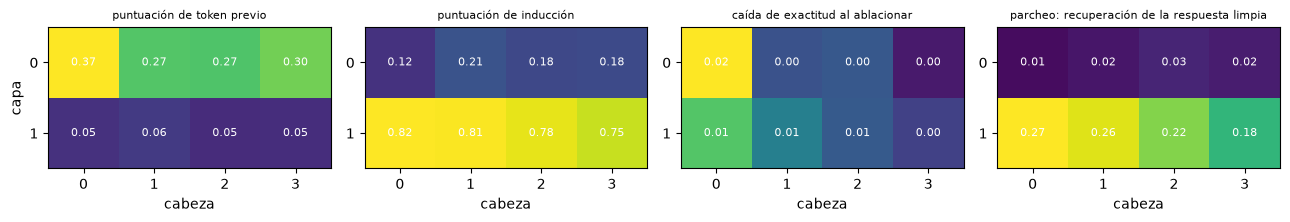

exactitud cuando se ablacionan las cuatro cabezas de la capa 1: 0.229; cuando se ablacionan las cuatro cabezas de la capa 0: 0.413
el parcheo usó 300 entradas que el modelo resuelve; exactitud de base en tokens repetidos 0.946
puntuación de token previo | capa 0: [0.37 0.27 0.27 0.3 ] | capa 1: [0.05 0.06 0.05 0.05]
puntuación de inducción | capa 0: [0.12 0.21 0.18 0.18] | capa 1: [0.82 0.81 0.78 0.75]
caída de exactitud al ablacionar | capa 0: [0.02 0.   0.   0.  ] | capa 1: [0.01 0.01 0.01 0.  ]
recuperación por parcheo | capa 0: [0.01 0.02 0.03 0.02] | capa 1: [0.27 0.26 0.22 0.18]


In [16]:
# 1) mirar los patrones de atención: puntuación de token previo (la consulta p atiende a p-1) y puntuación de inducción
#    (la consulta p, dentro del bloque repetido, atiende al token POSTERIOR a la aparición anterior del token actual)
cache = {}
with torch.no_grad(): lm(tt, cache=cache)
prev_score, ind_score = np.zeros((2, H)), np.zeros((2, H))
for l in range(2):
    att = cache[l][0]                                                           # (B, H, T, T)
    for i in range(len(tt)):
        k = int(nn_[i]); qs = torch.arange(k, 2 * k - 1)                        # posiciones de consulta en el bloque repetido (token actual = t[q-k])
        ind_score[l] += (att[i][:, qs, qs - k + 1].mean(1)).numpy() / len(tt)
        prev_score[l] += (att[i][:, torch.arange(1, L), torch.arange(0, L - 1)].mean(1)).numpy() / len(tt)

# 2) ablacionar cada cabeza (sustituir su salida por su media sobre el lote) y medir la exactitud en los tokens repetidos
base = repeat_acc(); abl = np.zeros((2, H))
for l in range(2):
    for h in range(H):
        mean_z = cache[l][1][:, h].mean(0, keepdim=True).expand(len(tt), -1, -1)
        abl[l, h] = base - repeat_acc({(l, h): mean_z})

# 3) parcheo de activaciones: entrada limpia  [a0..a7][a0..a7]  frente a entrada corrompida donde se cambia el token posterior a a_j en el PRIMER bloque
def patching(n=300, seed=7):
    g = torch.Generator().manual_seed(seed); rec = np.zeros((2, H)); used = 0
    for _ in range(n):
        a = torch.randperm(V, generator=g)[:9]                               # 9 símbolos distintos: a0..a7 más uno de reserva
        clean = torch.cat([a[:8], a[:8], torch.randint(0, V, (8,), generator=g)])[None]
        j = int(torch.randint(1, 7, (1,), generator=g)); q = 8 + j              # posición de consulta: el token a_j en la repetición; la respuesta es a_{j+1}
        corrupt = clean.clone(); corrupt[0, j + 1] = a[8]                      # en el primer bloque, a_{j+1} -> símbolo de reserva
        ans_clean, ans_corr = int(a[j + 1]), int(a[8])
        cc, cr = {}, {}
        with torch.no_grad():
            lc = lm(clean, cache=cc)[0, q]; lr_ = lm(corrupt, cache=cr)[0, q]
            gap = lambda lg: float(lg[ans_clean] - lg[ans_corr])
            if gap(lc) - gap(lr_) < 1.0: continue                              # omitir entradas que el modelo no resuelve
            used += 1
            for l in range(2):
                for h in range(H):
                    lp = lm(corrupt, edit={(l, h): cc[l][1][:, h]})[0, q]       # parchear la salida de UNA cabeza desde la ejecución limpia
                    rec[l, h] += (gap(lp) - gap(lr_)) / (gap(lc) - gap(lr_))
    return rec / max(used, 1), used
rec, used = patching()

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, (name, M_) in zip(axes, [("puntuación de token previo", prev_score), ("puntuación de inducción", ind_score), ("caída de exactitud al ablacionar", abl), ("parcheo: recuperación de la respuesta limpia", rec)]):
    im = ax.imshow(M_, cmap="viridis", vmin=0); ax.set_title(name, fontsize=8); ax.set_xlabel("cabeza"); ax.set_yticks([0, 1]); ax.set_xticks(range(H)); ax.grid(False)
    for (r_, c_), v in np.ndenumerate(M_): ax.text(c_, r_, f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
axes[0].set_ylabel("capa"); plt.tight_layout(); plt.show()
all1 = {(1, h): cache[1][1][:, h].mean(0, keepdim=True).expand(len(tt), -1, -1) for h in range(H)}
all0 = {(0, h): cache[0][1][:, h].mean(0, keepdim=True).expand(len(tt), -1, -1) for h in range(H)}
print(f"exactitud cuando se ablacionan las cuatro cabezas de la capa 1: {repeat_acc(all1):.3f}; cuando se ablacionan las cuatro cabezas de la capa 0: {repeat_acc(all0):.3f}")
print(f"el parcheo usó {used} entradas que el modelo resuelve; exactitud de base en tokens repetidos {base:.3f}")
for name, M_ in [("puntuación de token previo", prev_score), ("puntuación de inducción", ind_score), ("caída de exactitud al ablacionar", abl), ("recuperación por parcheo", rec)]:
    print(name, "| capa 0:", np.round(M_[0], 2), "| capa 1:", np.round(M_[1], 2))

**Lectura.** El juguete aprende la tarea: exactitud en los tokens repetidos de 0.946 frente a 0.042 del azar, y la pérdida baja de 3.42 a 0.14 en 500 pasos. Las cabezas son como predice la historia de la inducción. En la capa 0 cada cabeza pone algo de atención en el token previo (puntuaciones de 0.27 a 0.37, frente a 0.05 en la capa 1), y en la capa 1 las cuatro cabezas tienen una puntuación de inducción de 0.75 a 0.82 frente a 0.12 a 0.21 en la capa 0. Las pruebas causales muestran algo menos ordenado que la imagen de los libros de texto: ablacionar cualquier cabeza individual cuesta como mucho 2 puntos de exactitud, pero ablacionar las cuatro cabezas de la capa 1 baja la exactitud a 0.229 y ablacionar las cuatro de la capa 0 a 0.413. Las cuatro cabezas de inducción son **copias redundantes**, así que la ablación de una sola cabeza subestima su papel. El parcheo de activaciones coincide: parchear una cabeza de la capa 1 desde la ejecución limpia restaura del 18 al 27 % de la respuesta limpia (aproximadamente el 93 % entre las cuatro), mientras que una sola cabeza de la capa 0 restaura como mucho el 3 %, porque la información del token previo está repartida entre cuatro cabezas. Esta es la principal lección práctica del análisis de circuitos: la evidencia causal necesita intervenciones diseñadas para la estructura (aquí, grupos enteros de cabezas). El juguete tiene un circuito fácil y limpio por diseño; los modelos de lenguaje reales tienen muchos circuitos superpuestos y los resultados allí son parciales. Una ejecución de entrenamiento.

### 8.2 Autoencoders dispersos y superposición

Una red a menudo necesita representar más características de las dimensiones que tiene. La **superposición** (Elhage et al., [2022](https://transformer-circuits.pub/2022/toy_model/index.html)) es la observación de que puede hacerlo guardando las características como *direcciones no ortogonales*, apoyándose en que pocas características están activas a la vez. La consecuencia para la interpretabilidad es que **las neuronas individuales rara vez significan una sola cosa**: mezclan varias características ("polisemanticidad"). Un **autoencoder disperso** (SAE) es un remedio probado en modelos reales por Cunningham et al. ([2023](https://arxiv.org/abs/2309.08600)) y Bricken et al. ([2023](https://transformer-circuits.pub/2023/monosemantic-features/index.html)): se entrena un autoencoder ancho sobre las activaciones de una capa con una penalización (la norma $L_1$, la suma de valores absolutos) que hace el código **disperso**, con la esperanza de que cada unidad del código caiga sobre una característica verdadera. Las versiones a gran escala en modelos de frontera son un área de investigación activa; son prometedoras, pero su fiabilidad y utilidad se debaten.

Nuestro juguete es la prueba honesta más pequeña: 12 características "verdaderas" ocultas, cada una una dirección unitaria en solo 5 dimensiones (elegidas entre 2000 sorteos aleatorios para estar lo más separadas posible, de modo que no haya dos casi paralelas), cada una activa cerca del 8 % del tiempo con una intensidad aleatoria. Solo observamos la suma de 5 dimensiones. ¿Puede un SAE con 24 unidades encontrar las 12 direcciones? El análisis de componentes principales (PCA) es la línea base lineal: tiene solo 5 ejes, así que no puede.

In [17]:
torch.manual_seed(0); r = np.random.default_rng(0)
NF, DD, NL = 12, 5, 24
best = None
for _ in range(2000):                                                                          # conservar el sorteo mejor repartido
    cand = r.normal(size=(NF, DD)); cand /= np.linalg.norm(cand, axis=1, keepdims=True)
    worst = np.abs(cand @ cand.T - np.eye(NF)).max()
    if best is None or worst < best[0]: best = (worst, cand)
Fdir = best[1]                                                                                 # direcciones de las características verdaderas
def sample_acts(n, seed):
    rr = np.random.default_rng(seed)
    active = rr.random((n, NF)) < 0.08
    return ((active * rr.uniform(0.5, 1.5, (n, NF))) @ Fdir).astype(np.float32), active
Xa, act_true = sample_acts(40000, 1)
print(f"número medio de características verdaderas activas por muestra: {act_true.sum(1).mean():.2f}; |coseno| máximo entre dos direcciones verdaderas: {np.abs(Fdir @ Fdir.T - np.eye(NF)).max():.2f}")

class SAE(nn.Module):
    def __init__(s):
        super().__init__(); s.enc = nn.Linear(DD, NL); s.dec = nn.Parameter(torch.randn(NL, DD) * 0.3)
    def forward(s, x):
        z = F.relu(s.enc(x)); d = s.dec / s.dec.norm(dim=1, keepdim=True); return z @ d, z, d

def train_sae(l1, steps=2500):
    torch.manual_seed(0); sae = SAE(); opt = torch.optim.Adam(sae.parameters(), 3e-3); Xt_ = torch.tensor(Xa)
    for step in range(steps):
        b = Xt_[torch.randint(0, len(Xt_), (512,))]; rec, z, d = sae(b)
        loss = F.mse_loss(rec, b) + l1 * z.abs().sum(1).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return sae

t0 = time.time(); out = []
Xte_sae = torch.tensor(sample_acts(5000, 2)[0])
for l1 in [0.0, 0.1, 0.2, 0.4]:
    sae = train_sae(l1)
    with torch.no_grad(): rec, z, d = sae(Xte_sae)
    cos = np.abs(Fdir @ d.numpy().T)                                              # (característica verdadera, unidad del SAE)
    best = cos.max(1)
    out.append(dict(l1_penalty=l1, features_recovered=int((best > 0.95).sum()), mean_best_cosine=best.mean(), active_units_per_sample=float((z > 1e-3).float().sum(1).mean()),
                    reconstruction_R2=1 - float(F.mse_loss(rec, Xte_sae) / Xte_sae.var())))
print(pd.DataFrame(out).round(3).to_string(index=False)); print(f"entrenamiento del SAE: {time.time() - t0:.0f} s")
# línea base PCA: ¿cuánto se alinean 5 ejes ortogonales con las 12 direcciones verdaderas?
U = np.linalg.svd(Xa, full_matrices=False)[2]
print(f"PCA (5 ejes): características con un eje de |coseno| > 0.95 = {(np.abs(Fdir @ U.T).max(1) > 0.95).sum()}, mejor coseno medio {np.abs(Fdir @ U.T).max(1).mean():.2f}")

número medio de características verdaderas activas por muestra: 0.96; |coseno| máximo entre dos direcciones verdaderas: 0.73


 l1_penalty  features_recovered  mean_best_cosine  active_units_per_sample  reconstruction_R2
        0.0                   1             0.817                   15.380              1.000
        0.1                   9             0.953                    2.835              0.889
        0.2                  11             0.987                    1.638              0.707
        0.4                   9             0.969                    0.744              0.300
entrenamiento del SAE: 6 s
PCA (5 ejes): características con un eje de |coseno| > 0.95 = 0, mejor coseno medio 0.75


**Lectura.** Sin penalización de dispersión el autoencoder reconstruye perfectamente (R2 = 1.00) pero usa 15 de sus 24 unidades en cada muestra y se alinea con solo 1 de las 12 direcciones verdaderas (mejor coseno medio 0.82): la reconstrucción por sí sola no hace aparecer características. El PCA, con sus 5 ejes ortogonales, no se alinea con ninguna (mejor coseno medio 0.75). Con una penalización L1 de 0.1 el código es disperso (2.8 unidades activas) y se recuperan 9 de las 12 direcciones verdaderas con coseno superior a 0.95; con 0.2 son 11 de 12 (mejor coseno medio 0.99) al precio de la calidad de reconstrucción (R2 0.71); con 0.4 la reconstrucción se hunde (R2 0.30) y la recuperación baja a 9. Así que hay un compromiso real entre **dispersión** y **fidelidad**, y la mejor penalización se encuentra mirando la verdad de referencia, que en un modelo de lenguaje real no tenemos. El juguete también es fácil por diseño: las direcciones se eligieron bien separadas, las características son independientes y aproximadamente una está activa cada vez, y ajustamos la lista de penalizaciones con estos mismos datos. Las activaciones reales tienen características correlacionadas, jerárquicas y continuas, y por eso los resultados a gran escala (Bricken et al., Cunningham et al.) necesitan millones de unidades y una inspección cuidadosa, humana y automática, y por eso sigue abierta la cuestión de cuánto capturan del cómputo del modelo. Una semilla; el número recuperado puede cambiar en uno entre ejecuciones y máquinas.

## 9. Límites y mal uso de las explicaciones

Lo que advierten las mediciones anteriores, reunido en un solo lugar.

* **Una explicación describe el modelo, no el mundo.** El ejemplo de la glucosa mostró una característica que recibe crédito sin tener ningún efecto causal. La atribución responde a "qué usa el modelo", y solo una intervención o el conocimiento del dominio responde a "qué cambiaría el resultado".
* **Muchos métodos parecen correctos y no lo son.** La sección 4.1 es la lección de Adebayo et al.: un mapa atractivo no es evidencia. Ejecuta siempre una prueba de aleatorización y una de borrado antes de confiar en un método con un modelo nuevo, y compara con una línea base sin modelo como los bordes o el brillo.
* **Distintos métodos discrepan, y la discrepancia no es solo ruido.** La saliencia, SmoothGrad, los gradientes integrados y Grad-CAM dieron mapas distintos para la misma imagen y predicción (la matriz de correlaciones de la sección 4). Elegir el que "se ve mejor" es **sesgo de confirmación** disfrazado de análisis.
* **Las pruebas de fidelidad tienen sus propios artefactos.** Borrar píxeles crea imágenes que el modelo nunca vio (una entrada fuera de distribución), lo que puede cambiar su salida por razones ajenas al contenido borrado. Hooker et al. ([2019](https://arxiv.org/abs/1806.10758)) lo abordan reentrenando tras la eliminación (ROAR, RemOve And Retrain).
* **Las referencias y las características correlacionadas cambian la respuesta.** Los gradientes integrados y los valores de Shapley dependen de la elección de la referencia o de los datos de fondo. Con características correlacionadas el crédito se reparte de maneras que dependen de si se rompe la correlación (intervencional) o se respeta (condicional).
* **Las sondas muestran presencia, no uso; la atención muestra encaminamiento, no razones; un circuito hallado en un juguete puede no existir a escala.** Los resultados mecanicistas en modelos grandes son parciales y se comprueban a mano.
* **Las explicaciones pueden servir para blanquear una decisión.** Una historia post-hoc pegada a un modelo que nunca se diseñó para ser entendido da falsa seguridad, y una explicación puede mostrarse a una persona que entonces confía en el modelo *más* de lo que justifica su exactitud. Rudin ([2019](https://arxiv.org/abs/1811.10154)) recomienda dejar de explicar cajas negras en decisiones de alto riesgo y usar modelos interpretables cuando sean lo bastante precisos. La sección 2 es un pequeño ejemplo de ese argumento.
* **Las explicaciones se pueden manipular.** Slack et al. ([2020](https://arxiv.org/abs/1911.02508)) construyeron clasificadores que se comportan de forma discriminatoria con entradas reales pero parecen inocentes para LIME y SHAP, porque esos métodos consultan el modelo con entradas perturbadas poco realistas que el clasificador puede reconocer.

**Un protocolo práctico.** (1) Di qué decisión apoya la explicación y quién la lee. (2) Prefiere un modelo interpretable cuando sea lo bastante preciso. (3) Para una caja negra, usa al menos dos métodos y una línea base sin modelo. (4) Ejecuta una prueba de aleatorización y una de borrado o reentrenamiento. (5) Intenta **romper tu propia explicación** plantando un defecto conocido, como en la sección 5. (6) Presenta las explicaciones como hipótesis sobre el modelo, con su incertidumbre, y verifícalas por intervención cuando puedas.

## Ideas clave

* **Interpretable por diseño frente a post-hoc, global frente a local, explicación frente a afirmación causal.** Mantén estas tres distinciones en cualquier discusión; la mayor parte de la confusión viene de mezclarlas.
* **Un modelo legible es una vara de medir.** En una tarea con regla conocida, la regresión logística y el árbol dieron la línea base con la que se pudieron puntuar los métodos de atribución.
* **Los valores de Shapley son exactos pero exponenciales; el muestreo y los gradientes son los caminos prácticos.** Los gradientes integrados y Shapley cumplen la completitud, que verificamos numéricamente; el gradiente por entrada no. LIME depende de la elección del ancho de núcleo y de perturbaciones aleatorias, así que comprueba su estabilidad.
* **Nunca confíes en un mapa sin una prueba.** La prueba de aleatorización y la curva de borrado separan los métodos que reflejan el modelo de los que reflejan la imagen; una línea base sin modelo muestra lo que "bueno" tiene que superar.
* **La atribución puede encontrar un atajo plantado**, y la caída de exactitud medida al quitar la señal muestra cuánto daño hace. El arreglo está en los datos (descorrelacionar la señal), no en la explicación.
* **Los pesos de atención no son explicaciones.** Los rankings por gradiente y por oclusión se acercan más a lo que usa el modelo; las sondas muestran qué es legible linealmente, no qué se usa.
* **La interpretabilidad mecanicista hace afirmaciones causales por intervención.** La ablación y el parcheo de activaciones localizaron el circuito de inducción en un juguete; los autoencoders dispersos pueden recuperar en un juguete características almacenadas en superposición, y si esto escala es una cuestión de investigación abierta.
* **Las explicaciones tienen límites y se pueden usar mal.** Trátalas como hipótesis sobre el modelo, pruébalas y prefiere modelos interpretables para decisiones de alto riesgo.

## Ejercicios

1. En la sección 2 añade un segundo señuelo `glucose2` que sea una copia ruidosa de `age`. ¿Cómo reparten el crédito entre características correlacionadas los valores de Shapley y la importancia por permutación? ¿La suma exacta de Shapley sigue siendo igual a $f(x) - \mathbb{E}[f]$?
2. Cambia el fondo de Shapley de 100 filas aleatorias a una sola fila (la media). ¿Cuánto cambian los valores? ¿Qué dice eso sobre "el" valor de Shapley?
3. En la sección 3 implementa LIME con características discretizadas (en intervalos) en lugar de perturbaciones gaussianas. ¿Es más o menos estable entre semillas?
4. Añade el **gradiente por entrada** y **SmoothGrad** a la prueba de cordura de la sección 4.1. ¿Qué métodos la superan? Prueba a aleatorizar solo `c1` (de abajo arriba) en lugar de la cascada desde arriba.
5. En la sección 4.2 sustituye el relleno negro por el promedio de la imagen y vuelve a medir las áreas de borrado. ¿Cambian los rankings? ¿Por qué importa el relleno?
6. En la sección 5 reduce el parche a 2 por 2 píxeles, o dale una correlación del 90 % con la etiqueta en lugar del 100 %. ¿Cómo cambia la caída de exactitud al quitar la señal, y el juego del señalamiento aún la encuentra?
7. En la sección 6 prueba Grad-CAM en otra capa (`layer3`). ¿Cómo cambia el mapa y qué pasa con el área de borrado?
8. En la sección 7.2 usa la atención de la **primera capa** en lugar de la última. ¿Se correlaciona mejor con la oclusión? Después promedia la atención solo sobre la cabeza más importante.
9. En la sección 8.1 entrena durante 100 pasos y vuelve a mirar la puntuación de inducción. ¿En qué paso aparecen las cabezas (pista: registra la curva de pérdida y las puntuaciones cada 50 pasos)?
10. En la sección 8.2 cambia el número de características verdaderas de 12 a 6 y luego a 30. ¿Cómo cambia la recuperación del SAE y en qué punto deja de funcionar?

## Referencias

* Rudin, C. (2019). Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. *Nature Machine Intelligence* 1, 206-215. arXiv:1811.10154: https://arxiv.org/abs/1811.10154
* Ribeiro, M. T., Singh, S. and Guestrin, C. (2016). "Why should I trust you?": explaining the predictions of any classifier (LIME). arXiv:1602.04938: https://arxiv.org/abs/1602.04938
* Lundberg, S. M. and Lee, S.-I. (2017). A unified approach to interpreting model predictions (SHAP). arXiv:1705.07874: https://arxiv.org/abs/1705.07874
* Sundararajan, M., Taly, A. and Yan, Q. (2017). Axiomatic attribution for deep networks (integrated gradients). arXiv:1703.01365: https://arxiv.org/abs/1703.01365
* Simonyan, K., Vedaldi, A. and Zisserman, A. (2014). Deep inside convolutional networks: visualising image classification models and saliency maps. arXiv:1312.6034: https://arxiv.org/abs/1312.6034
* Smilkov, D. et al. (2017). SmoothGrad: removing noise by adding noise. arXiv:1706.03825: https://arxiv.org/abs/1706.03825
* Selvaraju, R. R. et al. (2017). Grad-CAM: visual explanations from deep networks via gradient-based localization. *ICCV*. arXiv:1610.02391: https://arxiv.org/abs/1610.02391
* Adebayo, J. et al. (2018). Sanity checks for saliency maps. *NeurIPS*. arXiv:1810.03292: https://arxiv.org/abs/1810.03292
* Samek, W. et al. (2017). Evaluating the visualization of what a deep neural network has learned. arXiv:1509.06321: https://arxiv.org/abs/1509.06321
* Petsiuk, V., Das, A. and Saenko, K. (2018). RISE: randomized input sampling for explanation of black-box models. arXiv:1806.07421: https://arxiv.org/abs/1806.07421
* Zhang, J. et al. (2018). Top-down neural attention by excitation backprop (the pointing game). *IJCV*. arXiv:1608.00507: https://arxiv.org/abs/1608.00507
* Hooker, S. et al. (2019). A benchmark for interpretability methods in deep neural networks (ROAR). arXiv:1806.10758: https://arxiv.org/abs/1806.10758
* Slack, D. et al. (2020). Fooling LIME and SHAP: adversarial attacks on post hoc explanation methods. *AIES*. arXiv:1911.02508: https://arxiv.org/abs/1911.02508
* Jain, S. and Wallace, B. C. (2019). Attention is not explanation. *NAACL*. arXiv:1902.10186: https://arxiv.org/abs/1902.10186
* Wiegreffe, S. and Pinter, Y. (2019). Attention is not not explanation. *EMNLP*. arXiv:1908.04626: https://arxiv.org/abs/1908.04626
* Hewitt, J. and Liang, P. (2019). Designing and interpreting probes with control tasks. *EMNLP*. arXiv:1909.03368: https://arxiv.org/abs/1909.03368
* Olsson, C. et al. (2022). In-context learning and induction heads. *Transformer Circuits Thread*: https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html
* Elhage, N. et al. (2022). Toy models of superposition. *Transformer Circuits Thread*: https://transformer-circuits.pub/2022/toy_model/index.html
* Bricken, T. et al. (2023). Towards monosemanticity: decomposing language models with dictionary learning. *Transformer Circuits Thread*: https://transformer-circuits.pub/2023/monosemantic-features/index.html
* Cunningham, H. et al. (2023). Sparse autoencoders find highly interpretable features in language models. arXiv:2309.08600: https://arxiv.org/abs/2309.08600
* He, K. et al. (2015). Deep residual learning for image recognition. arXiv:1512.03385: https://arxiv.org/abs/1512.03385
* Sanh, V. et al. (2019). DistilBERT, a distilled version of BERT. arXiv:1910.01108: https://arxiv.org/abs/1910.01108
* Xiao, H., Rasul, K. and Vollgraf, R. (2017). Fashion-MNIST. arXiv:1708.07747: https://arxiv.org/abs/1708.07747 (licencia MIT; [ficha del dataset](https://huggingface.co/datasets/zalando-datasets/fashion_mnist))
* Casanueva, I. et al. (2020). Efficient intent detection with dual sentence encoders (Banking77). arXiv:2003.04807: https://arxiv.org/abs/2003.04807 (CC BY 4.0; [ficha del dataset](https://huggingface.co/datasets/PolyAI/banking77))
* Herramientas: [biblioteca SHAP](https://github.com/shap/shap), [Captum (interpretabilidad para PyTorch)](https://captum.ai), [TransformerLens](https://github.com/TransformerLensOrg/TransformerLens), [datos de scikit-image](https://scikit-image.org/docs/stable/api/skimage.data.html)
* Curso hermano: [Python 1001, frameworks de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/)

In [18]:
print(f"tiempo total de ejecución del notebook: {(time.time() - T_START) / 60:.1f} minutos")

tiempo total de ejecución del notebook: 2.4 minutos
